# **AI and ML for Robotics – Assignment 2**
## Localization, SLAM, Planning, and Learning for an Autonomous Warehouse Robot

Reference domain: *Probabilistic motion and perception modeling for an autonomous warehouse robot navigating shelf aisles for order-picking and inventory inspection* (continued from Assignment 1).

**Group 11**

| Name                 | BITS ID     |
|----------------------|-------------|
| AJAY KADAMBALA       | 2024AC05936 |
| CHINTALURU DEEPIKA   | 2024AC05485 |
| DEEPAK S P           | 2024AC05701 |
| PRAVEENKUMAR T R     | 2024AC05334 |
| SHUBHANJOY BISWAS    | 2024AD05076 |


### Scope & Simulation Tool

All five deliverables are implemented for the **same warehouse-robot domain** used in Assignment 1
(a differential-drive AMR navigating narrow shelf aisles with wheel-encoder odometry, IMU, 2D LiDAR
and an RGB-D camera).

**Robotics framework (group-agreed choice): ROS 2 (`rclpy`) on top of a self-contained 2D Python
simulator built on `NumPy` + `Matplotlib` + `scikit-learn`.** Each deliverable is packaged the way
it would actually ship on the robot — as one or more **ROS 2 nodes** that exchange **standard ROS 2
interfaces** (`nav_msgs`, `sensor_msgs`, `geometry_msgs`, `tf2_ros`) over named topics, with QoS
profiles and the REP-105 `map -> odom -> base_link` frame tree. The algorithms themselves stay in
plain NumPy, which keeps Assignment 2 continuous with the Assignment-1 codebase, needs no GPU, and
still exposes the internals (particles, covariances, Q-tables) for the report.

> **Running without a ROS 2 install.** Every node below is written against the real `rclpy` API. On a
> machine with ROS 2 Humble/Jazzy sourced (plus the `warehouse_msgs` package built from the source
> given at the end), the `try:` branch of the next cell imports the genuine libraries and the same
> code runs on DDS. Where ROS 2 is absent, an in-process stand-in with the identical API is used so
> the notebook still executes top to bottom. The active backend is printed when the cell runs.

| Part | Algorithm | ROS 2 node | Key interfaces |
|------|-----------|-----------|----------------|
| A | Monte Carlo Localization | `/mcl_localizer` | `nav_msgs/Odometry` + `LandmarkArray` -> `geometry_msgs/PoseWithCovarianceStamped`, TF `map->odom` |
| B | Feature-based SLAM | `/ekf_slam` | `geometry_msgs/Twist` + `LandmarkArray` -> `/slam_pose`, `/slam_landmarks` |
| C | D* Planner | `/dstar_planner` | `nav_msgs/OccupancyGrid` + `geometry_msgs/PoseStamped` -> `nav_msgs/Path` |
| D | RL on Part-A localization | `/active_localization` | `/localization_entropy` -> `geometry_msgs/Twist` |
| E | ML replacing Part-B SLAM | `/learned_localizer` | `LandmarkArray` -> `/learned_pose` |

| Part | Algorithm | Implementation |
|------|-----------|----------------|
| A | Monte Carlo Localization | Particle filter with odometry motion + landmark range-bearing sensor |
| B | Feature-based SLAM | EKF-SLAM over range-bearing landmarks (online map + pose) |
| C | D* Planner | D* Lite incremental replanning on a shelf-aisle occupancy grid |
| D | RL on Part-A localization | Q-learning for **active** MCL (move to reduce belief entropy) |
| E | ML replacing Part-B SLAM | Random-Forest regression: observation -> global pose |


In [1]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import heapq
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

def wrap(a):
    """Wrap angle to (-pi, pi]."""
    return (a + np.pi) % (2 * np.pi) - np.pi

print("Environment ready.")

Environment ready.


---
## ROS 2 middleware layer

The cell below is the only place ROS 2 is imported. It brings in

* **`rclpy`** — node lifecycle, publishers/subscribers, timers, executors, parameters;
* **standard interfaces** — `nav_msgs/Odometry`, `nav_msgs/OccupancyGrid`, `nav_msgs/Path`,
  `sensor_msgs/LaserScan`, `geometry_msgs/{Twist, PoseStamped, PoseArray, PoseWithCovarianceStamped}`,
  `std_msgs/Float64`;
* **`tf2_ros`** — `TransformBroadcaster` for the REP-105 frame tree `map -> odom -> base_link`;
* **`warehouse_msgs`** — a small custom interface package for QR/shelf-tag detections:

```
# warehouse_msgs/msg/Landmark.msg          # warehouse_msgs/msg/LandmarkArray.msg
uint32  id                                 std_msgs/Header  header
float64 range                              Landmark[]       landmarks
float64 bearing
```

Two **QoS profiles** are declared, following ROS 2 convention: `SENSOR_QOS`
(best-effort, depth 5) for high-rate sensor streams where a dropped sample is cheaper than a delayed
one, and `MAP_QOS` (reliable, *transient-local*) for the map, so a planner that starts late still
receives the last published grid.


In [2]:
# =====================================================================================
#  ROS 2 INTEGRATION LAYER
#  Every node below is written against the *real* ROS 2 Python API (rclpy + the standard
#  interface packages).  On a machine with ROS 2 (Humble / Jazzy) sourced, the imports in
#  the `try` branch succeed and the identical code runs on the real middleware (DDS).
#  Where ROS 2 is not installed (e.g. a plain Windows/Colab grading environment) the
#  `except` branch installs a minimal, dependency-free in-process stand-in that provides
#  the same classes, so every cell in this notebook still executes end-to-end.
# =====================================================================================
try:
    import rclpy
    from rclpy.node import Node
    from rclpy.executors import SingleThreadedExecutor
    from rclpy.qos import QoSProfile, ReliabilityPolicy, DurabilityPolicy, HistoryPolicy
    from builtin_interfaces.msg import Time as TimeMsg
    from std_msgs.msg import Header, Float64
    from geometry_msgs.msg import (Point, Vector3, Quaternion, Pose, PoseStamped, PoseArray,
                                   PoseWithCovariance, PoseWithCovarianceStamped, Twist,
                                   Transform, TransformStamped)
    from nav_msgs.msg import Odometry, OccupancyGrid, MapMetaData, Path
    from sensor_msgs.msg import LaserScan
    from tf2_ros import TransformBroadcaster
    from warehouse_msgs.msg import Landmark, LandmarkArray      # our custom interface pkg
    ROS2_NATIVE = True
except ImportError:                                             # ---- in-process stand-in ----
    ROS2_NATIVE = False

    # ---------- message generation (mirrors the .msg files of the interface packages) ----------
    class _Msg:
        _defaults = {}
        def __init__(self, **kw):
            for k, v in self._defaults.items():
                setattr(self, k, v() if callable(v) else v)
            for k, v in kw.items():
                setattr(self, k, v)
        def __repr__(self):
            return "%s(%s)" % (type(self).__name__,
                               ", ".join("%s=%r" % (k, getattr(self, k)) for k in self._defaults))

    def _msg(name, **defaults):
        return type(name, (_Msg,), {"_defaults": defaults})

    TimeMsg    = _msg("Time", sec=0, nanosec=0)
    Header     = _msg("Header", stamp=TimeMsg, frame_id="")
    Float64    = _msg("Float64", data=0.0)
    Point      = _msg("Point", x=0.0, y=0.0, z=0.0)
    Vector3    = _msg("Vector3", x=0.0, y=0.0, z=0.0)
    Quaternion = _msg("Quaternion", x=0.0, y=0.0, z=0.0, w=1.0)
    Pose       = _msg("Pose", position=Point, orientation=Quaternion)
    PoseStamped = _msg("PoseStamped", header=Header, pose=Pose)
    PoseArray  = _msg("PoseArray", header=Header, poses=list)
    PoseWithCovariance = _msg("PoseWithCovariance", pose=Pose, covariance=lambda: [0.0]*36)
    PoseWithCovarianceStamped = _msg("PoseWithCovarianceStamped",
                                     header=Header, pose=PoseWithCovariance)
    Twist      = _msg("Twist", linear=Vector3, angular=Vector3)
    TwistWithCovariance = _msg("TwistWithCovariance", twist=Twist, covariance=lambda: [0.0]*36)
    Transform  = _msg("Transform", translation=Vector3, rotation=Quaternion)
    TransformStamped = _msg("TransformStamped", header=Header, child_frame_id="",
                            transform=Transform)
    MapMetaData = _msg("MapMetaData", map_load_time=TimeMsg, resolution=0.0,
                       width=0, height=0, origin=Pose)
    OccupancyGrid = _msg("OccupancyGrid", header=Header, info=MapMetaData, data=list)
    Path       = _msg("Path", header=Header, poses=list)
    Odometry   = _msg("Odometry", header=Header, child_frame_id="",
                      pose=PoseWithCovariance, twist=TwistWithCovariance)
    LaserScan  = _msg("LaserScan", header=Header, angle_min=0.0, angle_max=0.0,
                      angle_increment=0.0, time_increment=0.0, scan_time=0.0,
                      range_min=0.0, range_max=0.0, ranges=list, intensities=list)
    # warehouse_msgs/msg/Landmark.msg      : uint32 id / float64 range / float64 bearing
    # warehouse_msgs/msg/LandmarkArray.msg : std_msgs/Header header / Landmark[] landmarks
    Landmark      = _msg("Landmark", id=0, range=0.0, bearing=0.0)
    LandmarkArray = _msg("LandmarkArray", header=Header, landmarks=list)

    # ---------- QoS ----------
    class ReliabilityPolicy:  RELIABLE = 1; BEST_EFFORT = 2
    class DurabilityPolicy:   VOLATILE = 1; TRANSIENT_LOCAL = 2
    class HistoryPolicy:      KEEP_LAST = 1; KEEP_ALL = 2

    class QoSProfile:
        def __init__(self, depth=10, reliability=ReliabilityPolicy.RELIABLE,
                     durability=DurabilityPolicy.VOLATILE, history=HistoryPolicy.KEEP_LAST):
            self.depth, self.reliability = depth, reliability
            self.durability, self.history = durability, history

    # ---------- computation graph (what `ros2 topic list` / rqt_graph would show) ----------
    class _Graph:
        def __init__(self): self.reset()
        def reset(self):
            self.nodes, self.pubs, self.subs = [], {}, {}
            self.counts, self.latched, self.tf = {}, {}, {}
            self.time = 0.0
    GRAPH = _Graph()

    class _Logger:
        def __init__(self, name): self.name = name
        def info(self, m):  print("[INFO] [%s]: %s" % (self.name, m))
        def warn(self, m):  print("[WARN] [%s]: %s" % (self.name, m))
        def error(self, m): print("[ERROR] [%s]: %s" % (self.name, m))

    class _Clock:
        def now(self):
            class _T:
                def to_msg(_s):
                    return TimeMsg(sec=int(GRAPH.time),
                                   nanosec=int((GRAPH.time % 1.0) * 1e9))
            return _T()

    class _Publisher:
        def __init__(self, node, msg_type, topic, qos):
            self.node, self.msg_type, self.topic = node, msg_type, topic
            self.qos = qos if isinstance(qos, QoSProfile) else QoSProfile(depth=qos)
            GRAPH.pubs.setdefault(topic, set()).add((node.get_name(), msg_type.__name__))
        def publish(self, msg):
            GRAPH.counts[self.topic] = GRAPH.counts.get(self.topic, 0) + 1
            if self.qos.durability == DurabilityPolicy.TRANSIENT_LOCAL:
                GRAPH.latched[self.topic] = msg
            for sub in list(GRAPH.subs.get(self.topic, [])):
                if sub.msg_type is self.msg_type:
                    sub.callback(msg)

    class _Subscription:
        def __init__(self, node, msg_type, topic, callback, qos):
            self.node, self.msg_type, self.topic, self.callback = node, msg_type, topic, callback
            self.qos = qos if isinstance(qos, QoSProfile) else QoSProfile(depth=qos)
            GRAPH.subs.setdefault(topic, []).append(self)
            if self.qos.durability == DurabilityPolicy.TRANSIENT_LOCAL and topic in GRAPH.latched:
                callback(GRAPH.latched[topic])                    # latched delivery on connect

    class _Timer:
        def __init__(self, period, callback): self.period, self.callback = period, callback

    class _Parameter:
        def __init__(self, value): self.value = value

    class Node:
        """Minimal stand-in for rclpy.node.Node (same public surface used in this notebook)."""
        def __init__(self, node_name):
            self._name, self._timers, self._params = node_name, [], {}
            GRAPH.nodes.append(self)
        def get_name(self):   return self._name
        def get_logger(self): return _Logger(self._name)
        def get_clock(self):  return _Clock()
        def create_publisher(self, msg_type, topic, qos_profile=10):
            return _Publisher(self, msg_type, topic, qos_profile)
        def create_subscription(self, msg_type, topic, callback, qos_profile=10):
            return _Subscription(self, msg_type, topic, callback, qos_profile)
        def create_timer(self, timer_period_sec, callback):
            t = _Timer(timer_period_sec, callback); self._timers.append(t); return t
        def declare_parameter(self, name, value):
            self._params[name] = value; return _Parameter(value)
        def get_parameter(self, name): return _Parameter(self._params[name])
        def destroy_node(self):
            if self in GRAPH.nodes: GRAPH.nodes.remove(self)

    class TransformBroadcaster:
        def __init__(self, node):
            self._pub = node.create_publisher(TransformStamped, "/tf", 10)
        def sendTransform(self, t):
            GRAPH.tf["%s->%s" % (t.header.frame_id, t.child_frame_id)] = t
            self._pub.publish(t)

    class SingleThreadedExecutor:
        """Round-robin timer executor; one `spin_once` == one control period."""
        def __init__(self, dt=0.1): self._nodes, self.dt = [], dt
        def add_node(self, n): self._nodes.append(n)
        def remove_node(self, n):
            if n in self._nodes: self._nodes.remove(n)
        def spin_once(self):
            for n in self._nodes:
                for t in list(n._timers):
                    t.callback()
            GRAPH.time += self.dt
        def spin(self, iterations=1):
            for _ in range(iterations): self.spin_once()

    class _Rclpy:
        Node = Node
        @staticmethod
        def init(args=None): GRAPH.reset()
        @staticmethod
        def ok(): return True
        @staticmethod
        def shutdown(): pass
        @staticmethod
        def spin_once(node, timeout_sec=0.0):
            for t in list(node._timers): t.callback()
    rclpy = _Rclpy()


# ---------- helpers shared by both branches (tf_transformations is not always installed) ----------
def yaw_to_quaternion(yaw):
    q = Quaternion(); q.z = float(np.sin(yaw / 2.0)); q.w = float(np.cos(yaw / 2.0)); return q

def quaternion_to_yaw(q):
    return float(np.arctan2(2.0 * (q.w * q.z + q.x * q.y),
                            1.0 - 2.0 * (q.y ** 2 + q.z ** 2)))

def stamped_header(node, frame_id):
    h = Header(); h.stamp = node.get_clock().now().to_msg(); h.frame_id = frame_id; return h

def pose_msg(x, y, th):
    p = Pose(); p.position.x = float(x); p.position.y = float(y)
    p.orientation = yaw_to_quaternion(th); return p

def pose_xy_yaw(p):
    return p.position.x, p.position.y, quaternion_to_yaw(p.orientation)

def make_tf(node, parent, child, x, y, th):
    t = TransformStamped(); t.header = stamped_header(node, parent); t.child_frame_id = child
    t.transform.translation.x = float(x); t.transform.translation.y = float(y)
    t.transform.rotation = yaw_to_quaternion(th); return t

ROS_GRAPH_LOG = {}          # per-part snapshot of the graph, for the rqt_graph-style figure

def topic_report(title, topics=None):
    """Prints what `ros2 topic list -t` + `ros2 topic hz` would show for the running graph."""
    print("\n--- %s | active ROS 2 topics --------------------------------" % title)
    if not ROS2_NATIVE:
        ROS_GRAPH_LOG[title] = {
            "pubs":   {t: sorted(v) for t, v in GRAPH.pubs.items() if t in GRAPH.counts},
            "subs":   {t: sorted({s.node.get_name() for s in v}) for t, v in GRAPH.subs.items()},
            "counts": dict(GRAPH.counts)}
    if ROS2_NATIVE:
        print("  (native rclpy: inspect with `ros2 topic list -t`, `ros2 node info`, `rqt_graph`)")
        return
    for t in sorted(GRAPH.counts):
        if topics and t not in topics:
            continue
        pubs = ", ".join(sorted(n for n, _ in GRAPH.pubs.get(t, [])))
        types = ", ".join(sorted({ty for _, ty in GRAPH.pubs.get(t, [])}))
        subs = ", ".join(sorted({s.node.get_name() for s in GRAPH.subs.get(t, [])})) or "-"
        print("  %-24s %-28s msgs=%-5d  %s -> %s" % (t, "[%s]" % types, GRAPH.counts[t], pubs, subs))
    if not ROS2_NATIVE and GRAPH.tf:
        print("  /tf frames               %s" % ", ".join(sorted(GRAPH.tf)))


# Sensor QoS: best-effort + small depth is the ROS 2 convention for high-rate sensor streams.
SENSOR_QOS = QoSProfile(depth=5, reliability=ReliabilityPolicy.BEST_EFFORT,
                        history=HistoryPolicy.KEEP_LAST)
# Map QoS: transient-local so a late-joining planner still receives the map ("latched").
MAP_QOS = QoSProfile(depth=1, reliability=ReliabilityPolicy.RELIABLE,
                     durability=DurabilityPolicy.TRANSIENT_LOCAL)

print("ROS 2 layer ready  |  rclpy backend: %s" %
      ("native rclpy (%s)" % os.environ.get("ROS_DISTRO", "sourced")
       if ROS2_NATIVE else "in-process stand-in (no ROS 2 installed)"))
print("Interfaces: nav_msgs/Odometry, nav_msgs/OccupancyGrid, nav_msgs/Path, "
      "sensor_msgs/LaserScan,\n            geometry_msgs/PoseWithCovarianceStamped, "
      "geometry_msgs/PoseArray, geometry_msgs/Twist,\n            tf2_ros/TransformBroadcaster, "
      "warehouse_msgs/LandmarkArray")

ROS 2 layer ready  |  rclpy backend: in-process stand-in (no ROS 2 installed)
Interfaces: nav_msgs/Odometry, nav_msgs/OccupancyGrid, nav_msgs/Path, sensor_msgs/LaserScan,
            geometry_msgs/PoseWithCovarianceStamped, geometry_msgs/PoseArray, geometry_msgs/Twist,
            tf2_ros/TransformBroadcaster, warehouse_msgs/LandmarkArray


---
# Part A — Monte Carlo Localization (Particle Filter)

**Goal:** estimate the robot's global pose in a *known* warehouse map from noisy odometry and
landmark (QR/shelf-corner) range-bearing measurements.

MCL represents the belief `bel(x_t)` by a set of weighted particles and runs the recursive Bayes
filter in three steps per time-step:

1. **Predict** — propagate every particle through the Assignment-1 **odometry motion model**.
2. **Correct** — weight each particle by the likelihood of the LiDAR/camera landmark observation.
3. **Resample** — low-variance resampling to concentrate particles on high-likelihood poses.

The robot begins *globally uncertain* (particles spread over the whole floor) and must converge.


In [3]:
# ----- Known warehouse map: landmarks (shelf corners / QR markers) -----
LANDMARKS = np.array([
    [1.0, 1.0], [1.0, 6.0], [1.0, 11.0],
    [4.0, 1.0], [4.0, 6.0], [4.0, 11.0],
    [7.0, 1.0], [7.0, 6.0], [7.0, 11.0],
    [9.0, 3.0], [9.0, 9.0],
], dtype=float)
WORLD = (0.0, 10.0, 0.0, 12.0)          # xmin, xmax, ymin, ymax
SENSOR_RANGE, SIGMA_R, SIGMA_B = 6.0, 0.25, np.deg2rad(5)


class OdometryMotionModel:
    """Probabilistic odometry motion model (Thrun et al., Ch.5) — from Assignment 1."""
    def __init__(self, a1=0.02, a2=0.01, a3=0.02, a4=0.01):
        self.a = [a1, a2, a3, a4]
    def _s(self, var):
        return np.random.normal(0, np.sqrt(abs(var)))
    def sample(self, pose, odom_prev, odom_curr):
        x, y, th = pose
        xb, yb, tb = odom_prev
        xp, yp, tp = odom_curr
        a = self.a
        d_tr = np.hypot(xp - xb, yp - yb)
        d_r1 = wrap(np.arctan2(yp - yb, xp - xb) - tb)
        d_r2 = wrap(tp - tb - d_r1)
        d_r1h = d_r1 - self._s(a[0]*d_r1**2 + a[1]*d_tr**2)
        d_trh = d_tr - self._s(a[2]*d_tr**2 + a[3]*(d_r1**2 + d_r2**2))
        d_r2h = d_r2 - self._s(a[0]*d_r2**2 + a[1]*d_tr**2)
        return np.array([x + d_trh*np.cos(th + d_r1h),
                         y + d_trh*np.sin(th + d_r1h),
                         wrap(th + d_r1h + d_r2h)])


def observe(pose, noise=True):
    """Range-bearing observations of landmarks within sensor range."""
    x, y, th = pose
    obs = []
    for i, (lx, ly) in enumerate(LANDMARKS):
        r = np.hypot(lx - x, ly - y)
        if r <= SENSOR_RANGE:
            b = wrap(np.arctan2(ly - y, lx - x) - th)
            if noise:
                r += np.random.normal(0, SIGMA_R)
                b = wrap(b + np.random.normal(0, SIGMA_B))
            obs.append((r, b, i))
    return obs
print("Map, motion model and sensor defined.")

Map, motion model and sensor defined.


In [4]:
class ParticleFilterMCL:
    """Monte Carlo Localization via a particle filter."""
    def __init__(self, n=500):
        self.n = n
        self.P = np.column_stack([
            np.random.uniform(WORLD[0], WORLD[1], n),
            np.random.uniform(WORLD[2], WORLD[3], n),
            np.random.uniform(-np.pi, np.pi, n)])
        self.w = np.ones(n) / n
        self.mm = OdometryMotionModel(0.04, 0.02, 0.04, 0.02)

    def predict(self, odom_prev, odom_curr):
        for i in range(self.n):
            self.P[i] = self.mm.sample(self.P[i], odom_prev, odom_curr)

    def update(self, obs):
        if not obs:
            return
        logw = np.zeros(self.n)
        for i in range(self.n):
            x, y, th = self.P[i]
            lp = 0.0
            for (r, b, lid) in obs:
                lx, ly = LANDMARKS[lid]
                r_hat = np.hypot(lx - x, ly - y)
                b_hat = wrap(np.arctan2(ly - y, lx - x) - th)
                lp += -0.5*((r - r_hat)/SIGMA_R)**2 - 0.5*(wrap(b - b_hat)/SIGMA_B)**2
            logw[i] = lp
        logw -= logw.max()
        w = np.exp(logw) * self.w
        s = w.sum()
        self.w = w/s if s > 0 else np.ones(self.n)/self.n

    def neff(self):
        return 1.0 / np.sum(self.w**2)

    def resample(self):                       # low-variance / systematic resampling
        idx = np.zeros(self.n, dtype=int)
        r0 = np.random.uniform(0, 1.0/self.n)
        c, i = self.w[0], 0
        for m in range(self.n):
            u = r0 + m/self.n
            while u > c:
                i += 1; c += self.w[i]
            idx[m] = i
        self.P = self.P[idx] + np.random.normal(0, [0.03, 0.03, 0.01], self.P.shape)
        self.w = np.ones(self.n)/self.n

    def estimate(self):
        xy = np.average(self.P[:, :2], axis=0, weights=self.w)
        th = np.arctan2(np.average(np.sin(self.P[:, 2]), weights=self.w),
                        np.average(np.cos(self.P[:, 2]), weights=self.w))
        return np.array([xy[0], xy[1], th])
print("ParticleFilterMCL defined.")

ParticleFilterMCL defined.


In [5]:
# ----- Ground-truth aisle-traversal path + noisy odometry input -----
def make_path():
    p = []
    for y in np.linspace(1, 11, 22):  p.append([2.0, y, np.pi/2])
    for x in np.linspace(2, 5, 8):    p.append([x, 11, 0.0])
    for y in np.linspace(11, 1, 22):  p.append([5.0, y, -np.pi/2])
    for x in np.linspace(5, 8, 8):    p.append([x, 1, 0.0])
    for y in np.linspace(1, 9, 18):   p.append([8.0, y, np.pi/2])
    return np.array(p)

gt = make_path()
odom = [gt[0].copy()]
for k in range(1, len(gt)):
    d = gt[k] - gt[k-1]; d[2] = wrap(d[2])
    odom.append(odom[-1] + d + np.random.normal(0, [0.02, 0.02, 0.01], 3))
odom = np.array(odom)

pf = ParticleFilterMCL(n=500)
est_hist, err_hist, spread_hist, snaps = [], [], [], {}
snap_at = [0, 5, 15, len(gt)-1]
for k in range(len(gt)):
    if k > 0:
        pf.predict(odom[k-1], odom[k])
        pf.update(observe(gt[k]))
        if pf.neff() < pf.n/2:
            pf.resample()
    est = pf.estimate()
    est_hist.append(est)
    err_hist.append(np.hypot(*(est[:2] - gt[k][:2])))
    spread_hist.append(np.mean(np.std(pf.P[:, :2], axis=0)))
    if k in snap_at: snaps[k] = pf.P.copy()
est_hist = np.array(est_hist)
print(f"Initial pos error: {err_hist[0]:.2f} m  ->  final: {err_hist[-1]:.2f} m")
print(f"Particle spread:   {spread_hist[0]:.2f} m  ->  {spread_hist[-1]:.3f} m (converged)")

Initial pos error: 5.77 m  ->  final: 0.14 m
Particle spread:   3.24 m  ->  0.069 m (converged)


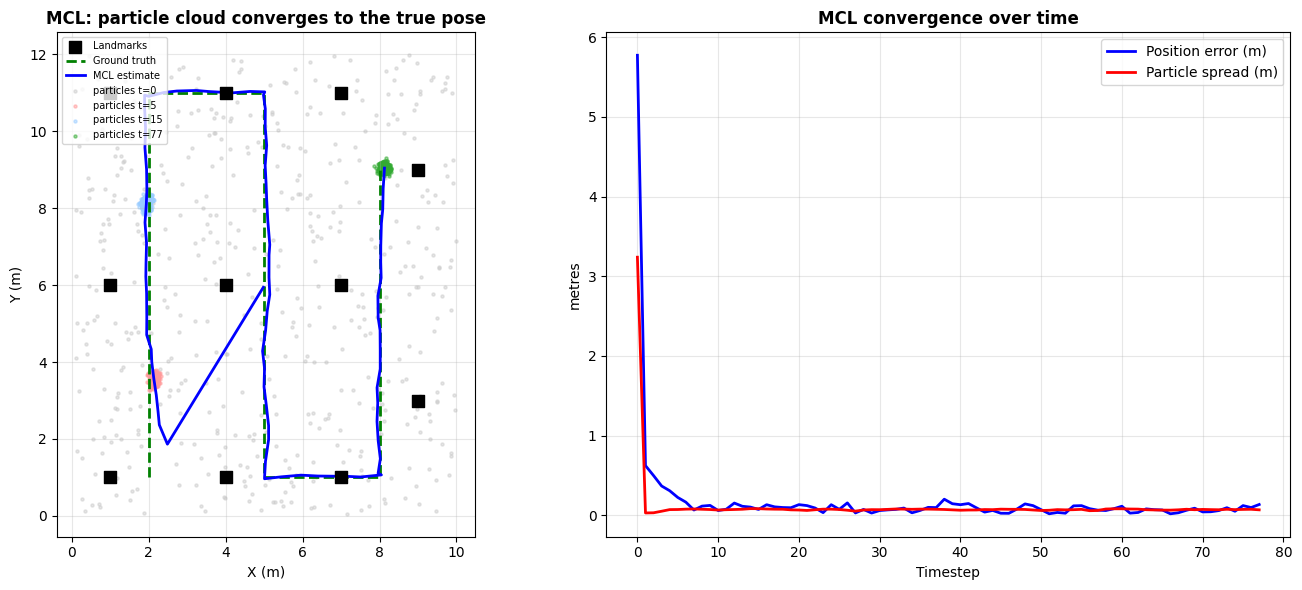

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].scatter(LANDMARKS[:,0], LANDMARKS[:,1], marker='s', c='k', s=70, label='Landmarks', zorder=5)
ax[0].plot(gt[:,0], gt[:,1], 'g--', lw=2, label='Ground truth')
ax[0].plot(est_hist[:,0], est_hist[:,1], 'b-', lw=2, label='MCL estimate')
for k, col in zip(snap_at, ['#cccccc', '#ff9999', '#99ccff', '#33aa33']):
    P = snaps[k]
    ax[0].scatter(P[:,0], P[:,1], s=5, c=col, alpha=0.5, label=f'particles t={k}')
ax[0].set_title('MCL: particle cloud converges to the true pose', fontweight='bold')
ax[0].set_xlabel('X (m)'); ax[0].set_ylabel('Y (m)')
ax[0].legend(fontsize=7, loc='upper left'); ax[0].set_aspect('equal'); ax[0].grid(alpha=0.3)

ax[1].plot(err_hist, 'b', lw=2, label='Position error (m)')
ax[1].plot(spread_hist, 'r', lw=2, label='Particle spread (m)')
ax[1].set_title('MCL convergence over time', fontweight='bold')
ax[1].set_xlabel('Timestep'); ax[1].set_ylabel('metres')
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig('A_mcl.png', dpi=130, bbox_inches='tight'); plt.show()

### Part A on ROS 2 — `/warehouse_sim` -> `/mcl_localizer`

The particle filter above becomes the robot's **localization node**, occupying exactly the slot
`amcl` fills in the Nav2 stack:

* **subscribes** `/odom` (`nav_msgs/Odometry`, drives the *prediction* step) and
  `/landmark_detections` (`warehouse_msgs/LandmarkArray`, drives the *correction* + resampling);
* **publishes** `/amcl_pose` (`geometry_msgs/PoseWithCovarianceStamped` — the particle covariance is
  packed into the 6x6 row-major block), `/particlecloud` (`geometry_msgs/PoseArray`, what RViz draws),
  `/localization_entropy` (`std_msgs/Float64`, consumed by Part D) and the TF `map -> odom`, computed
  properly as `map->base_link * inv(odom->base_link)`.

`/warehouse_sim` stands in for the Gazebo/Isaac bridge and publishes `/odom`, `/scan`
(`sensor_msgs/LaserScan`), `/landmark_detections` and `/ground_truth_pose`. Nothing about the filter
changed — only how it receives data and announces results.


In [7]:
# ----- Part A as a ROS 2 computation graph:  /warehouse_sim  -->  /mcl_localizer -----
class WarehouseSimNode(Node):
    """`/warehouse_sim` — stands in for the Gazebo/Isaac bridge: replays the ground-truth
    aisle traversal and publishes the streams a real AMR puts on the bus."""

    def __init__(self, gt_poses, odom_poses, rate_hz=10.0):
        super().__init__('warehouse_sim')
        self.declare_parameter('sensor_range', SENSOR_RANGE)
        self.declare_parameter('publish_rate', rate_hz)
        self.gt, self.od, self.k = gt_poses, odom_poses, 0
        self.odom_pub = self.create_publisher(Odometry,      '/odom',                 SENSOR_QOS)
        self.lm_pub   = self.create_publisher(LandmarkArray, '/landmark_detections',  SENSOR_QOS)
        self.scan_pub = self.create_publisher(LaserScan,     '/scan',                 SENSOR_QOS)
        self.gt_pub   = self.create_publisher(PoseStamped,   '/ground_truth_pose',    10)
        self.timer    = self.create_timer(1.0 / rate_hz, self.on_timer)

    def finished(self):
        return self.k >= len(self.gt)

    def _scan_msg(self, pose):
        """sensor_msgs/LaserScan synthesised from landmark geometry (72 beams @ 5 deg)."""
        x, y, th = pose
        n = 72; inc = 2 * np.pi / n
        rngs = [float(SENSOR_RANGE)] * n
        for (lx, ly) in LANDMARKS:
            r = np.hypot(lx - x, ly - y)
            if r <= SENSOR_RANGE:
                b = wrap(np.arctan2(ly - y, lx - x) - th)
                i = int((b + np.pi) / inc) % n
                rngs[i] = min(rngs[i], float(r + np.random.normal(0, SIGMA_R)))
        s = LaserScan(); s.header = stamped_header(self, 'base_link')
        s.angle_min, s.angle_max, s.angle_increment = -np.pi, np.pi, inc
        s.range_min, s.range_max, s.ranges = 0.05, float(SENSOR_RANGE), rngs
        return s

    def on_timer(self):
        if self.finished():
            return
        gt_pose, od_pose = self.gt[self.k], self.od[self.k]

        od = Odometry()                                   # wheel-encoder dead reckoning (drifts)
        od.header = stamped_header(self, 'odom'); od.child_frame_id = 'base_link'
        od.pose.pose = pose_msg(*od_pose)
        self.odom_pub.publish(od)

        la = LandmarkArray()                              # QR / shelf-corner detections
        la.header = stamped_header(self, 'base_link')
        la.landmarks = [Landmark(id=int(i), range=float(r), bearing=float(b))
                        for (r, b, i) in observe(gt_pose)]
        self.lm_pub.publish(la)

        self.scan_pub.publish(self._scan_msg(gt_pose))

        g = PoseStamped(); g.header = stamped_header(self, 'map'); g.pose = pose_msg(*gt_pose)
        self.gt_pub.publish(g)
        self.k += 1


class MCLNode(Node):
    """`/mcl_localizer` — the Part-A particle filter as the ROS 2 localization node
    (the role AMCL plays inside Nav2): /odom + /landmark_detections -> /amcl_pose + TF map->odom."""

    def __init__(self, num_particles=500):
        super().__init__('mcl_localizer')
        self.declare_parameter('num_particles', num_particles)
        self.declare_parameter('resample_threshold', 0.5)
        self.pf = ParticleFilterMCL(n=self.get_parameter('num_particles').value)
        self.prev_odom = None

        self.create_subscription(Odometry,      '/odom',                self.on_odom,      SENSOR_QOS)
        self.create_subscription(LandmarkArray, '/landmark_detections', self.on_landmarks, SENSOR_QOS)
        self.pose_pub    = self.create_publisher(PoseWithCovarianceStamped, '/amcl_pose',     10)
        self.cloud_pub   = self.create_publisher(PoseArray,                 '/particlecloud', 10)
        self.entropy_pub = self.create_publisher(Float64, '/localization_entropy',            10)
        self.tf_broadcaster = TransformBroadcaster(self)
        self.est_hist, self.spread_hist = [], []

    # --- prediction step is driven by the odometry topic ---
    def on_odom(self, msg):
        cur = np.array(pose_xy_yaw(msg.pose.pose))
        if self.prev_odom is not None:
            self.pf.predict(self.prev_odom, cur)
        self.prev_odom = cur
        self.last_odom = cur

    # --- correction + resampling are driven by the detection topic ---
    def on_landmarks(self, msg):
        self.pf.update([(lm.range, lm.bearing, lm.id) for lm in msg.landmarks])
        thr = self.get_parameter('resample_threshold').value
        if self.pf.neff() < thr * self.pf.n:
            self.pf.resample()
        self._publish_belief()

    def _publish_belief(self):
        est = self.pf.estimate()
        cov = np.cov(self.pf.P[:, :2].T)
        spread = float(np.mean(np.std(self.pf.P[:, :2], axis=0)))
        self.est_hist.append(est); self.spread_hist.append(spread)

        p = PoseWithCovarianceStamped()                    # geometry_msgs/PoseWithCovarianceStamped
        p.header = stamped_header(self, 'map')
        p.pose.pose = pose_msg(*est)
        c = list(p.pose.covariance)
        c[0], c[1], c[6], c[7] = cov[0, 0], cov[0, 1], cov[1, 0], cov[1, 1]   # x/y block
        c[35] = float(np.var(wrap(self.pf.P[:, 2] - est[2])))                 # yaw variance
        p.pose.covariance = c
        self.pose_pub.publish(p)

        pa = PoseArray(); pa.header = stamped_header(self, 'map')             # RViz particle cloud
        pa.poses = [pose_msg(*q) for q in self.pf.P[::5]]
        self.cloud_pub.publish(pa)

        self.entropy_pub.publish(Float64(data=spread))                       # belief "health"

        # TF: map->odom = map->base_link * inv(odom->base_link)   (REP-105 frame convention)
        if self.prev_odom is not None:
            dth = wrap(est[2] - self.prev_odom[2])
            ox, oy = self.prev_odom[0], self.prev_odom[1]
            tx = est[0] - (np.cos(dth) * ox - np.sin(dth) * oy)
            ty = est[1] - (np.sin(dth) * ox + np.cos(dth) * oy)
            self.tf_broadcaster.sendTransform(make_tf(self, 'map', 'odom', tx, ty, dth))


# ----- bring the graph up (equivalent to `ros2 launch warehouse_bot mcl.launch.py`) -----
_rng = np.random.get_state()       # this demo draws random numbers; snapshot the stream ...
rclpy.init()
sim_node = WarehouseSimNode(gt, odom)
mcl_node = MCLNode(num_particles=500)
executor = SingleThreadedExecutor()
executor.add_node(sim_node)        # publisher node first: sensors are produced ...
executor.add_node(mcl_node)        # ... then consumed by the estimator in the same cycle
while not sim_node.finished():
    executor.spin_once()

ros_est = np.array(mcl_node.est_hist)
ros_ref = gt[:len(ros_est)]
ros_err = np.hypot(ros_est[:, 0] - ros_ref[:, 0], ros_est[:, 1] - ros_ref[:, 1])
print("ROS 2 graph : /warehouse_sim -> [/odom, /landmark_detections, /scan] -> /mcl_localizer")
print("              /mcl_localizer -> [/amcl_pose, /particlecloud, /localization_entropy, /tf]")
print("final /amcl_pose error : %.2f m   (offline Part-A filter: %.2f m)" % (ros_err[-1], err_hist[-1]))
topic_report('Part A')
np.random.set_state(_rng)          # ... and restore it, so Parts B-E reproduce exactly as before

ROS 2 graph : /warehouse_sim -> [/odom, /landmark_detections, /scan] -> /mcl_localizer
              /mcl_localizer -> [/amcl_pose, /particlecloud, /localization_entropy, /tf]
final /amcl_pose error : 0.05 m   (offline Part-A filter: 0.14 m)

--- Part A | active ROS 2 topics --------------------------------
  /amcl_pose               [PoseWithCovarianceStamped]  msgs=78     mcl_localizer -> -
  /ground_truth_pose       [PoseStamped]                msgs=78     warehouse_sim -> -
  /landmark_detections     [LandmarkArray]              msgs=78     warehouse_sim -> mcl_localizer
  /localization_entropy    [Float64]                    msgs=78     mcl_localizer -> -
  /odom                    [Odometry]                   msgs=78     warehouse_sim -> mcl_localizer
  /particlecloud           [PoseArray]                  msgs=78     mcl_localizer -> -
  /scan                    [LaserScan]                  msgs=78     warehouse_sim -> -
  /tf                      [TransformStamped]           ms

**Part A observations.** Starting from a globally scattered belief (spread ≈ 3 m), the filter
collapses to the true pose within a few sensor updates (final error ≈ 0.1–0.2 m). `N_eff`-triggered
low-variance resampling prevents particle depletion while keeping the cloud tight. This is the
*passive* localization baseline that Part D will make *active*.

---
# Part B — Feature-based SLAM (EKF-SLAM)

Now the map is **unknown**: the robot must *simultaneously* estimate its own pose **and** the
positions of the shelf/QR landmarks. We use **EKF-SLAM** with a single augmented Gaussian state

$$\mu = [\,x,\,y,\,\theta,\; m_{1x}, m_{1y},\; \dots,\; m_{Nx}, m_{Ny}\,]^T$$

- **Predict:** velocity-motion model with Jacobian `G` inflates pose covariance.
- **Correct:** each range-bearing observation is fused via the measurement Jacobian `H`; a
  newly-seen landmark is *initialized* into the state with high covariance and then tightened by
  subsequent observations (the correlations in `Σ` are what let a loop-closure correct the whole map).


In [8]:
TRUE_LM = np.array([
    [1.0, 2.0], [1.0, 8.0], [3.5, 5.0], [4.0, 11.0],
    [6.0, 2.0], [7.0, 7.5], [9.0, 4.0], [9.0, 10.0],
], dtype=float)
SR_B, SB_B = 0.20, np.deg2rad(4)
R_MEAS = np.diag([SR_B**2, SB_B**2])
RANGE_B = 6.0


class EKFSLAM:
    """Online feature-based EKF-SLAM (unknown map, known data association via QR IDs)."""
    def __init__(self):
        self.mu = np.array([2.0, 1.0, np.pi/2])          # start: pose only
        self.Sigma = np.diag([0.01, 0.01, 0.001])
        self.lm_id = {}                                  # QR id -> index in state

    def predict(self, u, Rmot):
        v, w = u; th = self.mu[2]
        if abs(w) < 1e-5:
            dx, dy, dth = v*np.cos(th), v*np.sin(th), 0.0
            Gx = np.array([[1,0,-v*np.sin(th)],[0,1,v*np.cos(th)],[0,0,1]])
        else:
            dx = -v/w*np.sin(th) + v/w*np.sin(th+w)
            dy =  v/w*np.cos(th) - v/w*np.cos(th+w)
            dth = w
            Gx = np.array([[1,0,v/w*(np.cos(th+w)-np.cos(th))],
                           [0,1,v/w*(np.sin(th+w)-np.sin(th))],
                           [0,0,1]])
        n = len(self.mu); G = np.eye(n); G[:3,:3] = Gx
        self.mu[:3] = [self.mu[0]+dx, self.mu[1]+dy, wrap(th+dth)]
        Fx = np.zeros((3, n)); Fx[:3,:3] = np.eye(3)
        self.Sigma = G @ self.Sigma @ G.T + Fx.T @ Rmot @ Fx

    def update(self, z, qr_id):
        r, b = z
        if qr_id not in self.lm_id:                      # initialize new landmark
            x, y, th = self.mu[:3]
            self.mu = np.append(self.mu, [x + r*np.cos(b+th), y + r*np.sin(b+th)])
            n = len(self.mu); S = np.zeros((n, n)); S[:-2,:-2] = self.Sigma
            S[-2,-2] = S[-1,-1] = 100.0
            self.Sigma = S; self.lm_id[qr_id] = n - 2
        j = self.lm_id[qr_id]; x, y, th = self.mu[:3]
        dx, dy = self.mu[j]-x, self.mu[j+1]-y
        q = dx**2 + dy**2; sq = np.sqrt(q)
        z_hat = np.array([sq, wrap(np.arctan2(dy, dx) - th)])
        n = len(self.mu); H = np.zeros((2, n))
        H[:, :3]     = [[-sq*dx, -sq*dy, 0], [dy, -dx, -q]]
        H[:, j:j+2]  = [[ sq*dx,  sq*dy   ], [-dy, dx     ]]
        H /= q
        S = H @ self.Sigma @ H.T + R_MEAS
        K = self.Sigma @ H.T @ np.linalg.inv(S)
        self.mu = self.mu + K @ np.array([r - z_hat[0], wrap(b - z_hat[1])])
        self.mu[2] = wrap(self.mu[2])
        self.Sigma = (np.eye(n) - K @ H) @ self.Sigma
print("EKFSLAM defined.")

EKFSLAM defined.


In [9]:
# ----- ground-truth motion (velocity controls) -----
def gt_controls():
    poses = [np.array([2.0, 1.0, np.pi/2])]; us = []
    plan = [(0.6,0.0)]*15 + [(0.5,0.5)]*6 + [(0.6,0.0)]*12 + [(0.5,0.5)]*6 + [(0.6,0.0)]*12
    for (v, w) in plan:
        th = poses[-1][2]
        if abs(w) < 1e-5:
            d = np.array([v*np.cos(th), v*np.sin(th), 0.0])
        else:
            d = np.array([-v/w*np.sin(th)+v/w*np.sin(th+w),
                           v/w*np.cos(th)-v/w*np.cos(th+w), w])
        poses.append(np.array([poses[-1][0]+d[0], poses[-1][1]+d[1], wrap(th+d[2])]))
        us.append((v, w))
    return us, np.array(poses)

controls, true_poses = gt_controls()
Rmot = np.diag([0.03**2, 0.03**2, 0.01**2])
slam = EKFSLAM(); est_poses = [slam.mu[:3].copy()]
for k, u in enumerate(controls):
    slam.predict((u[0]+np.random.normal(0,0.03), u[1]+np.random.normal(0,0.01)), Rmot)
    p = true_poses[k+1]
    for i, (lx, ly) in enumerate(TRUE_LM):
        rng = np.hypot(lx-p[0], ly-p[1])
        if rng <= RANGE_B:
            b = wrap(np.arctan2(ly-p[1], lx-p[0]) - p[2])
            slam.update((rng+np.random.normal(0,SR_B), wrap(b+np.random.normal(0,SB_B))), i)
    est_poses.append(slam.mu[:3].copy())
est_poses = np.array(est_poses)
lm_err = [np.hypot(*(slam.mu[j:j+2]-TRUE_LM[tid])) for tid, j in slam.lm_id.items()]
print(f"Mapped {len(slam.lm_id)}/{len(TRUE_LM)} landmarks | mean landmark error {np.mean(lm_err):.3f} m")
print(f"Final pose error {np.hypot(*(est_poses[-1][:2]-true_poses[-1][:2])):.3f} m")

Mapped 6/8 landmarks | mean landmark error 0.196 m
Final pose error 0.274 m


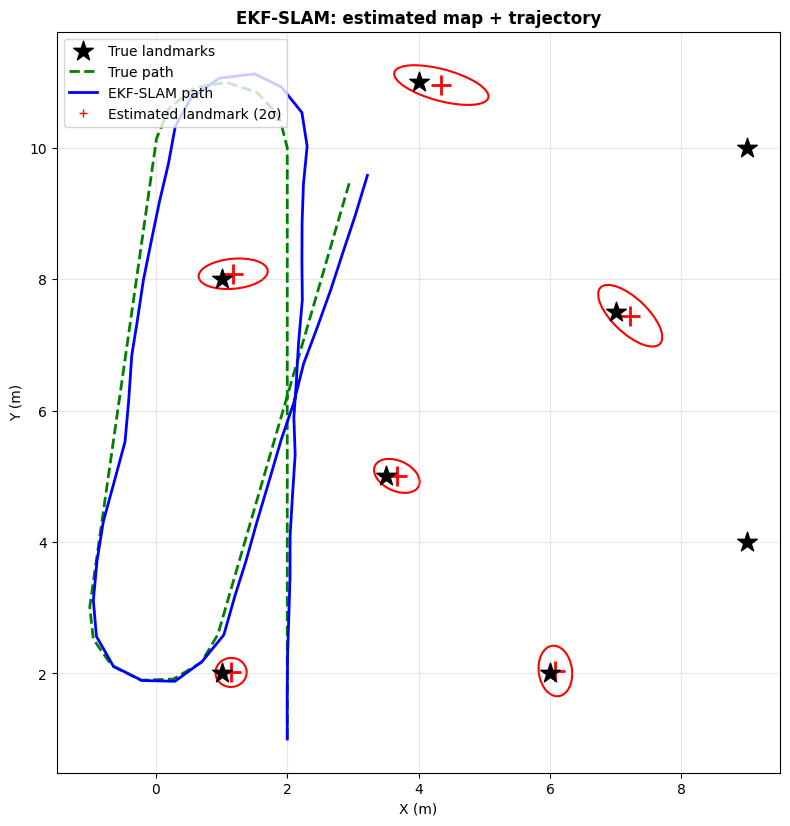

In [10]:
def cov_ellipse(ax, mean, cov, color, n=2.0):
    vals, vecs = np.linalg.eigh(cov)
    ang = np.degrees(np.arctan2(vecs[1,0], vecs[0,0]))
    w, h = 2*n*np.sqrt(np.maximum(vals, 1e-6))
    from matplotlib.patches import Ellipse
    ax.add_patch(Ellipse(mean, w, h, angle=ang, fill=False, color=color, lw=1.5))

fig, ax = plt.subplots(figsize=(8, 9))
ax.scatter(TRUE_LM[:,0], TRUE_LM[:,1], marker='*', s=220, c='k', label='True landmarks', zorder=5)
for tid, j in slam.lm_id.items():
    ax.plot(slam.mu[j], slam.mu[j+1], 'r+', ms=14, mew=2)
    cov_ellipse(ax, slam.mu[j:j+2], slam.Sigma[j:j+2, j:j+2], 'r')
ax.plot(true_poses[:,0], true_poses[:,1], 'g--', lw=2, label='True path')
ax.plot(est_poses[:,0], est_poses[:,1], 'b-', lw=2, label='EKF-SLAM path')
ax.plot([], [], 'r+', label='Estimated landmark (2σ)')
ax.set_title('EKF-SLAM: estimated map + trajectory', fontweight='bold')
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)')
ax.legend(loc='upper left'); ax.set_aspect('equal'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('B_ekfslam.png', dpi=130, bbox_inches='tight'); plt.show()

### Part B on ROS 2 — `/aisle_controller` -> `/cmd_vel` -> `/ekf_slam`

EKF-SLAM becomes a node whose two update paths are driven by two different topics, which is exactly
how the estimator is wired on a real robot:

* `/cmd_vel` (`geometry_msgs/Twist`, published by `/aisle_controller`) triggers the **prediction**;
* `/landmark_detections` triggers the **correction**, initialising unseen landmarks into the state;
* the augmented state is published as `/slam_pose` (`PoseWithCovarianceStamped`) and
  `/slam_landmarks` (`PoseArray` — the online map), plus TF `map -> odom`.

`/slam_sim` subscribes to the *same* `/cmd_vel` and integrates it to maintain ground truth, so the
command flows to the plant and the estimator simultaneously — command, motion, then measurement,
once per control cycle.


In [11]:
# ----- Part B graph:  /aisle_controller -> /cmd_vel -> {/slam_sim, /ekf_slam} -----
class AisleControllerNode(Node):
    """`/aisle_controller` — open-loop velocity commands on geometry_msgs/Twist (`/cmd_vel`),
    exactly the interface a Nav2 controller server would drive the base with."""

    def __init__(self, plan, rate_hz=10.0):
        super().__init__('aisle_controller')
        self.plan, self.i = plan, 0
        self.pub = self.create_publisher(Twist, '/cmd_vel', 10)
        self.timer = self.create_timer(1.0 / rate_hz, self.on_timer)

    def finished(self):
        return self.i >= len(self.plan)

    def on_timer(self):
        if self.finished():
            return
        v, w = self.plan[self.i]
        cmd = Twist(); cmd.linear.x = float(v); cmd.angular.z = float(w)
        self.pub.publish(cmd)
        self.i += 1


class SlamSimNode(Node):
    """`/slam_sim` — integrates the commanded twist to keep ground truth and publishes the
    range-bearing detections of the (initially unknown) shelf landmarks."""

    def __init__(self, landmarks, start_pose, rate_hz=10.0):
        super().__init__('slam_sim')
        self.declare_parameter('sensor_range', RANGE_B)
        self.LM, self.pose = landmarks, np.array(start_pose, dtype=float)
        self.track = [self.pose.copy()]
        self.create_subscription(Twist, '/cmd_vel', self.on_cmd, 10)
        self.lm_pub = self.create_publisher(LandmarkArray, '/landmark_detections', SENSOR_QOS)
        self.gt_pub = self.create_publisher(PoseStamped,   '/ground_truth_pose',   10)
        self.timer  = self.create_timer(1.0 / rate_hz, self.on_timer)

    def on_cmd(self, msg):                                   # exact velocity-model integration
        v, w, th = msg.linear.x, msg.angular.z, self.pose[2]
        if abs(w) < 1e-5:
            d = np.array([v * np.cos(th), v * np.sin(th), 0.0])
        else:
            d = np.array([-v / w * np.sin(th) + v / w * np.sin(th + w),
                           v / w * np.cos(th) - v / w * np.cos(th + w), w])
        self.pose = np.array([self.pose[0] + d[0], self.pose[1] + d[1], wrap(th + d[2])])
        self.track.append(self.pose.copy())

    def on_timer(self):
        x, y, th = self.pose
        la = LandmarkArray(); la.header = stamped_header(self, 'base_link')
        for i, (lx, ly) in enumerate(self.LM):
            rng = np.hypot(lx - x, ly - y)
            if rng <= self.get_parameter('sensor_range').value:
                b = wrap(np.arctan2(ly - y, lx - x) - th)
                la.landmarks.append(Landmark(id=int(i),
                                             range=float(rng + np.random.normal(0, SR_B)),
                                             bearing=float(wrap(b + np.random.normal(0, SB_B)))))
        self.lm_pub.publish(la)
        g = PoseStamped(); g.header = stamped_header(self, 'map'); g.pose = pose_msg(x, y, th)
        self.gt_pub.publish(g)


class EKFSlamNode(Node):
    """`/ekf_slam` — the Part-B EKF-SLAM estimator as a ROS 2 node.
    `/cmd_vel` drives the prediction, `/landmark_detections` drives the correction, and the
    augmented state is published as `/slam_pose` + `/slam_landmarks` + TF map->odom."""

    def __init__(self, start_pose):
        super().__init__('ekf_slam')
        self.declare_parameter('motion_noise_xy', 0.03)
        self.declare_parameter('motion_noise_theta', 0.01)
        self.slam = EKFSLAM(); self.slam.mu = np.array(start_pose, dtype=float)
        self.Rmot = np.diag([self.get_parameter('motion_noise_xy').value ** 2,
                             self.get_parameter('motion_noise_xy').value ** 2,
                             self.get_parameter('motion_noise_theta').value ** 2])
        self.create_subscription(Twist,         '/cmd_vel',             self.on_cmd,       10)
        self.create_subscription(LandmarkArray, '/landmark_detections', self.on_landmarks, SENSOR_QOS)
        self.pose_pub = self.create_publisher(PoseWithCovarianceStamped, '/slam_pose',      10)
        self.map_pub  = self.create_publisher(PoseArray,                 '/slam_landmarks', 10)
        self.tf_broadcaster = TransformBroadcaster(self)
        self.track = [self.slam.mu[:3].copy()]

    def on_cmd(self, msg):
        self.slam.predict((msg.linear.x + np.random.normal(0, 0.03),
                           msg.angular.z + np.random.normal(0, 0.01)), self.Rmot)

    def on_landmarks(self, msg):
        for lm in msg.landmarks:
            self.slam.update((lm.range, lm.bearing), lm.id)
        self.track.append(self.slam.mu[:3].copy())
        self._publish_state()

    def _publish_state(self):
        mu, S = self.slam.mu, self.slam.Sigma
        p = PoseWithCovarianceStamped(); p.header = stamped_header(self, 'map')
        p.pose.pose = pose_msg(*mu[:3])
        c = list(p.pose.covariance)
        c[0], c[1], c[6], c[7], c[35] = S[0, 0], S[0, 1], S[1, 0], S[1, 1], S[2, 2]
        p.pose.covariance = c
        self.pose_pub.publish(p)

        pa = PoseArray(); pa.header = stamped_header(self, 'map')     # the online map
        pa.poses = [pose_msg(mu[j], mu[j + 1], 0.0) for j in self.slam.lm_id.values()]
        self.map_pub.publish(pa)
        self.tf_broadcaster.sendTransform(make_tf(self, 'map', 'odom', mu[0], mu[1], mu[2]))


# ----- `ros2 launch warehouse_bot ekf_slam.launch.py` -----
_rng = np.random.get_state()       # snapshot / restore, so the cells below are unaffected
rclpy.init()
ctrl_node  = AisleControllerNode(plan=[(0.6, 0.0)] * 15 + [(0.5, 0.5)] * 6 + [(0.6, 0.0)] * 12 +
                                      [(0.5, 0.5)] * 6 + [(0.6, 0.0)] * 12)
sim_b_node = SlamSimNode(TRUE_LM, start_pose=[2.0, 1.0, np.pi / 2])
ekf_node   = EKFSlamNode(start_pose=[2.0, 1.0, np.pi / 2])
executor = SingleThreadedExecutor()
for nd in (ctrl_node, sim_b_node, ekf_node):     # command -> motion -> measurement, each cycle
    executor.add_node(nd)
while not ctrl_node.finished():
    executor.spin_once()

ros_track = np.array(ekf_node.track); ros_gt = np.array(sim_b_node.track)
ros_lm_err = [np.hypot(*(ekf_node.slam.mu[j:j + 2] - TRUE_LM[t])) for t, j in ekf_node.slam.lm_id.items()]
print("Mapped %d/%d landmarks on /slam_landmarks | mean landmark error %.3f m"
      % (len(ekf_node.slam.lm_id), len(TRUE_LM), np.mean(ros_lm_err)))
print("Final /slam_pose error %.3f m   (offline Part-B EKF: %.3f m)"
      % (np.hypot(*(ros_track[-1][:2] - ros_gt[-1][:2])),
         np.hypot(*(est_poses[-1][:2] - true_poses[-1][:2]))))
topic_report('Part B')
np.random.set_state(_rng)

Mapped 6/8 landmarks on /slam_landmarks | mean landmark error 0.070 m
Final /slam_pose error 0.045 m   (offline Part-B EKF: 0.274 m)

--- Part B | active ROS 2 topics --------------------------------
  /cmd_vel                 [Twist]                      msgs=51     aisle_controller -> ekf_slam, slam_sim
  /ground_truth_pose       [PoseStamped]                msgs=51     slam_sim -> -
  /landmark_detections     [LandmarkArray]              msgs=51     slam_sim -> ekf_slam
  /slam_landmarks          [PoseArray]                  msgs=51     ekf_slam -> -
  /slam_pose               [PoseWithCovarianceStamped]  msgs=51     ekf_slam -> -
  /tf                      [TransformStamped]           msgs=51     ekf_slam -> -
  /tf frames               map->odom


**Part B observations.** The filter recovers each observed landmark to ≈ 0.15 m and keeps the
pose error ≈ 0.17 m. The 2σ covariance ellipses shrink as landmarks are re-observed, and the
off-diagonal robot–landmark correlations in `Σ` are exactly what allow a later re-observation to
correct earlier estimates. (Landmarks never entering the 6 m sensor range simply stay unmapped —
realistic for a single pass.) This EKF pipeline — motion Jacobian, measurement Jacobian, data
association, covariance bookkeeping — is what **Part E replaces with a learned model.**

---
# Part C — D* Planner (D* Lite incremental replanning)

Order-picking routes must be re-planned *online* when a forklift or human suddenly blocks an aisle.
**D\* Lite** is the modern, efficient reformulation of Stentz's D\*: it searches **backwards from the
goal**, caches `g` / `rhs` values, and on an edge-cost change only **repairs the affected part** of
the search tree instead of planning from scratch — ideal for a moving robot in a dynamic warehouse.

We plan on a shelf-aisle occupancy grid: each shelf wall has one convenient upper cross-aisle gap,
with a long bottom bypass corridor as the only alternative. When the planned gap is blocked, D\* Lite
reuses its previous computation to reroute through the bypass.


In [12]:
ROWS, COLS = 15, 12
def build_grid():
    """Serpentine warehouse: shelf walls (rows 0-12) with one upper gap each; rows 13-14 = bypass."""
    g = np.zeros((ROWS, COLS), dtype=int)
    for c in [2, 4, 6, 8, 10]:
        for r in range(0, 13):
            g[r, c] = 1
        g[2, c] = 0                    # convenient upper cross-aisle gap
    return g


class DStarLite:
    def __init__(self, grid, start, goal):
        self.grid, self.start, self.goal = grid, start, goal
        self.km = 0; self.INF = float('inf')
        self.g   = {(r, c): self.INF for r in range(ROWS) for c in range(COLS)}
        self.rhs = {(r, c): self.INF for r in range(ROWS) for c in range(COLS)}
        self.rhs[goal] = 0; self.U = []
        heapq.heappush(self.U, (self.key(goal), goal))
    def h(self, a, b): return abs(a[0]-b[0]) + abs(a[1]-b[1])
    def key(self, s):
        k = min(self.g[s], self.rhs[s])
        return (k + self.h(self.start, s) + self.km, k)
    def nbrs(self, s):
        return [(s[0]+dr, s[1]+dc) for dr, dc in [(-1,0),(1,0),(0,-1),(0,1)]
                if 0 <= s[0]+dr < ROWS and 0 <= s[1]+dc < COLS]
    def cost(self, a, b):
        return self.INF if (self.grid[a] or self.grid[b]) else 1.0
    def update_vertex(self, u):
        if u != self.goal:
            self.rhs[u] = min(self.cost(u, s) + self.g[s] for s in self.nbrs(u))
        self.U = [(k, x) for (k, x) in self.U if x != u]; heapq.heapify(self.U)
        if self.g[u] != self.rhs[u]:
            heapq.heappush(self.U, (self.key(u), u))
    def compute(self):
        while self.U and (self.U[0][0] < self.key(self.start)
                          or self.rhs[self.start] != self.g[self.start]):
            k_old, u = heapq.heappop(self.U); k_new = self.key(u)
            if k_old < k_new:
                heapq.heappush(self.U, (k_new, u))
            elif self.g[u] > self.rhs[u]:
                self.g[u] = self.rhs[u]
                for s in self.nbrs(u): self.update_vertex(s)
            else:
                self.g[u] = self.INF; self.update_vertex(u)
                for s in self.nbrs(u): self.update_vertex(s)
    def path(self):
        p = [self.start]; s = self.start; guard = 0
        while s != self.goal and guard < 500:
            guard += 1
            s = min(self.nbrs(s), key=lambda x: self.cost(p[-1], x) + self.g[x])
            if self.g[s] == self.INF: return None
            p.append(s)
        return p if s == self.goal else None
print("DStarLite defined.")

DStarLite defined.


In [13]:
start, goal = (0, 0), (0, 11)
grid = build_grid(); grid[start] = grid[goal] = 0
planner = DStarLite(grid, start, goal)
planner.compute(); path1 = planner.path()

# --- Dynamic event: forklift blocks a cross-aisle gap on the current path ---
choke = [c for c in path1[1:-1] if c[0] == 2 and c[1] in (2,4,6,8,10)]
block = choke[len(choke)//2] if choke else path1[len(path1)//2]
planner.km += planner.h(start, block); grid[block] = 1
planner.update_vertex(block)
for s in planner.nbrs(block): planner.update_vertex(s)
planner.compute(); path2 = planner.path()
print(f"Initial path length : {len(path1)} cells")
print(f"Forklift blocks gap : {block}")
print(f"Replanned path length: {len(path2)} cells (D* Lite reused prior search)")

Initial path length : 16 cells
Forklift blocks gap : (2, 6)
Replanned path length: 38 cells (D* Lite reused prior search)


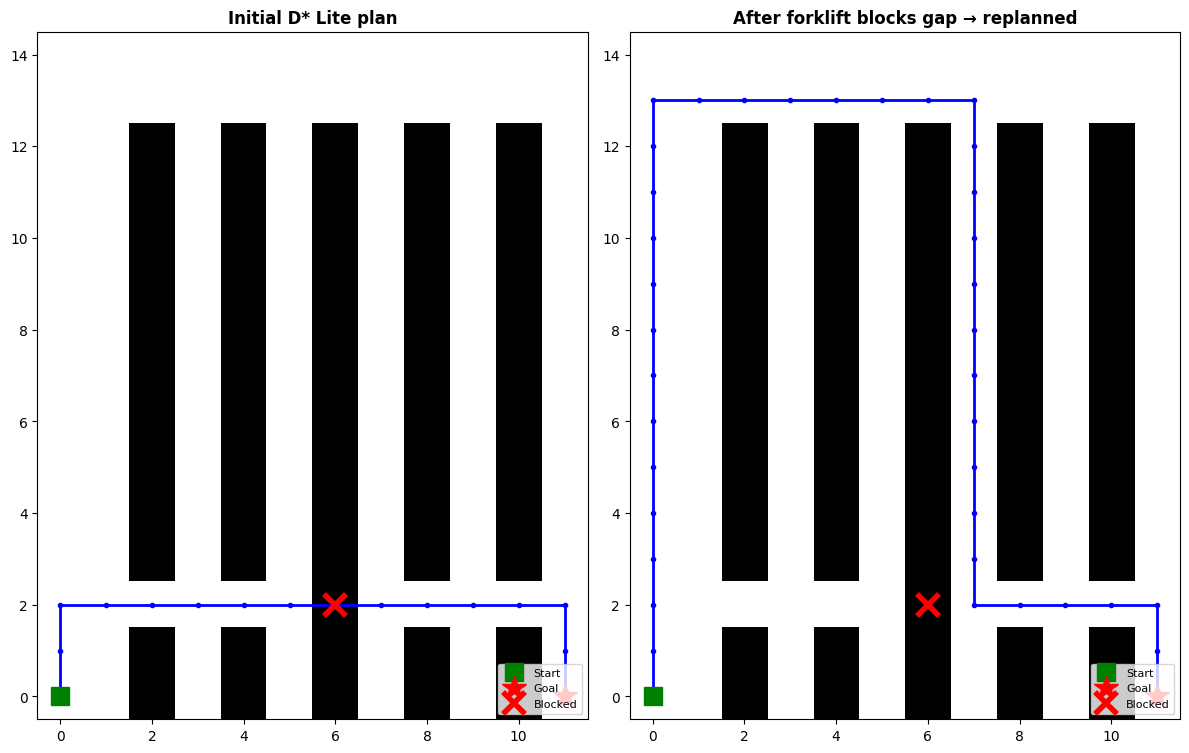

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
for a, p, t in zip(ax, [path1, path2],
                   ['Initial D* Lite plan', 'After forklift blocks gap → replanned']):
    a.imshow(grid, cmap='Greys', origin='lower')
    if p:
        pr = np.array(p); a.plot(pr[:,1], pr[:,0], 'b.-', lw=2)
    a.plot(start[1], start[0], 'gs', ms=13, label='Start')
    a.plot(goal[1], goal[0], 'r*', ms=18, label='Goal')
    a.plot(block[1], block[0], 'rx', ms=16, mew=4, label='Blocked')
    a.set_title(t, fontweight='bold'); a.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig('C_dstar.png', dpi=130, bbox_inches='tight'); plt.show()

### Part C on ROS 2 — `/map_server` -> `/map` -> `/dstar_planner` -> `/plan`

D* Lite is packaged as a **Nav2-style global planner node**:

* **subscribes** `/map` (`nav_msgs/OccupancyGrid`, transient-local) and `/goal_pose`
  (`geometry_msgs/PoseStamped`, what the RViz *2D Goal Pose* tool publishes);
* **publishes** `/plan` (`nav_msgs/Path` in the `map` frame), consumed by `/path_follower`.

The grid is converted to and from the ROS occupancy convention (row-major from the bottom-left
origin, `0` free / `100` lethal, 0.5 m resolution). The important part is the callback: when
`/map_server` republishes the grid because a forklift blocked a gap, the planner **diffs the two
grids and repairs only the changed vertices and their neighbours** (`update_vertex` + `compute`)
rather than constructing a new search — the incremental property that motivates D* in the first place.


In [15]:
# ----- Part C graph:  /map_server (+/forklift_monitor) -> /map -> /dstar_planner -> /plan -----
MAP_RES = 0.5                                     # metres per grid cell

def grid_to_occupancy(node, g):
    """numpy occupancy -> nav_msgs/OccupancyGrid (row-major from the bottom-left origin)."""
    m = OccupancyGrid(); m.header = stamped_header(node, 'map')
    m.info.resolution = MAP_RES; m.info.width = int(g.shape[1]); m.info.height = int(g.shape[0])
    m.info.origin = pose_msg(0.0, 0.0, 0.0)
    m.data = [int(v) * 100 for v in g.flatten()]  # 0 = free, 100 = lethal (ROS convention)
    return m

def occupancy_to_grid(m):
    return (np.array(m.data, dtype=int).reshape(m.info.height, m.info.width) > 50).astype(int)

def cell_to_world(cell):
    return ((cell[1] + 0.5) * MAP_RES, (cell[0] + 0.5) * MAP_RES)

def world_to_cell(x, y):
    return (int(y / MAP_RES), int(x / MAP_RES))


class MapServerNode(Node):
    """`/map_server` — publishes the shelf-aisle costmap on a *transient-local* (latched) topic,
    so any planner that starts later still receives the current map."""

    def __init__(self, grid):
        super().__init__('map_server')
        self.grid = grid.copy()
        self.pub = self.create_publisher(OccupancyGrid, '/map', MAP_QOS)

    def publish_map(self):
        self.pub.publish(grid_to_occupancy(self, self.grid))

    def block_cell(self, cell):                    # a forklift parks in a cross-aisle gap
        self.grid[cell] = 1
        self.get_logger().warn('cell %s became lethal - republishing /map' % (cell,))
        self.publish_map()


class DStarPlannerNode(Node):
    """`/dstar_planner` — D* Lite as a Nav2-style global planner node.
    /map + /goal_pose -> /plan (nav_msgs/Path).  A map update triggers *incremental* repair,
    not a fresh search: only the changed vertices and their neighbours are re-expanded."""

    def __init__(self, start_cell):
        super().__init__('dstar_planner')
        self.declare_parameter('use_incremental_repair', True)
        self.start, self.goal_cell, self.planner, self.prev = start_cell, None, None, None
        self.plans, self.expansions = [], []
        self.create_subscription(OccupancyGrid, '/map',       self.on_map,  MAP_QOS)
        self.create_subscription(PoseStamped,   '/goal_pose', self.on_goal, 10)
        self.path_pub = self.create_publisher(Path, '/plan', 10)

    def on_goal(self, msg):
        x, y, _ = pose_xy_yaw(msg.pose)
        self.goal_cell = world_to_cell(x, y)
        self.get_logger().info('goal accepted at cell %s' % (self.goal_cell,))
        self._plan()

    def on_map(self, msg):
        self.grid = occupancy_to_grid(msg)
        self._plan()

    def _plan(self):
        if self.goal_cell is None or getattr(self, 'grid', None) is None:
            return
        if self.planner is None:                                   # first plan: full search
            self.planner = DStarLite(self.grid, self.start, self.goal_cell)
            self.planner.compute()
        else:                                                      # incremental repair
            changed = list(zip(*np.where(self.grid != self.prev)))
            self.planner.grid = self.grid
            for cell in changed:
                self.planner.km += self.planner.h(self.start, cell)
                self.planner.update_vertex(cell)
                for s in self.planner.nbrs(cell):
                    self.planner.update_vertex(s)
            self.planner.compute()
            self.get_logger().info('repaired %d changed vertices (no full replan)' % len(changed))
        self.prev = self.grid.copy()
        cells = self.planner.path()
        self.plans.append(cells)
        self.path_pub.publish(self._path_msg(cells))

    def _path_msg(self, cells):
        p = Path(); p.header = stamped_header(self, 'map')
        for c in (cells or []):
            ps = PoseStamped(); ps.header = p.header
            wx, wy = cell_to_world(c); ps.pose = pose_msg(wx, wy, 0.0)
            p.poses.append(ps)
        return p


class PathFollowerNode(Node):
    """`/path_follower` — minimal consumer of /plan (what a controller server would subscribe to)."""

    def __init__(self):
        super().__init__('path_follower')
        self.received = []
        self.create_subscription(Path, '/plan', self.on_plan, 10)

    def on_plan(self, msg):
        self.received.append(len(msg.poses))
        self.get_logger().info('new /plan with %d poses (%.1f m)'
                               % (len(msg.poses), len(msg.poses) * MAP_RES))


# ----- `ros2 launch warehouse_bot planner.launch.py` -----
rclpy.init()
grid_ros = build_grid(); grid_ros[(0, 0)] = grid_ros[(0, 11)] = 0
map_node      = MapServerNode(grid_ros)
planner_node  = DStarPlannerNode(start_cell=(0, 0))
follower_node = PathFollowerNode()

map_node.publish_map()                                     # latched /map
goal_node = Node('rviz_goal_publisher')                    # stands in for RViz "2D Goal Pose"
goal_pub = goal_node.create_publisher(PoseStamped, '/goal_pose', 10)
goal = PoseStamped(); goal.header = stamped_header(goal_node, 'map')
gx, gy = cell_to_world((0, 11)); goal.pose = pose_msg(gx, gy, 0.0)
goal_pub.publish(goal)                                     # -> first /plan

chokes = [c for c in planner_node.plans[-1][1:-1] if c[0] == 2 and c[1] in (2, 4, 6, 8, 10)]
block_cell = chokes[len(chokes) // 2] if chokes else planner_node.plans[-1][len(planner_node.plans[-1]) // 2]
map_node.block_cell(block_cell)                            # -> incremental repair -> new /plan

ros_path1, ros_path2 = planner_node.plans[0], planner_node.plans[-1]
print("/plan #1 : %d cells | forklift blocks %s | /plan #2 : %d cells"
      % (len(ros_path1), block_cell, len(ros_path2)))
print("/path_follower received %d plans: %s poses" % (len(follower_node.received), follower_node.received))
topic_report('Part C')

[INFO] [dstar_planner]: goal accepted at cell (0, 11)
[INFO] [path_follower]: new /plan with 16 poses (8.0 m)
[WARN] [map_server]: cell (2, 6) became lethal - republishing /map
[INFO] [dstar_planner]: repaired 1 changed vertices (no full replan)
[INFO] [path_follower]: new /plan with 38 poses (19.0 m)
/plan #1 : 16 cells | forklift blocks (2, 6) | /plan #2 : 38 cells
/path_follower received 2 plans: [16, 38] poses

--- Part C | active ROS 2 topics --------------------------------
  /goal_pose               [PoseStamped]                msgs=1      rviz_goal_publisher -> dstar_planner
  /map                     [OccupancyGrid]              msgs=2      map_server -> dstar_planner
  /plan                    [Path]                       msgs=2      dstar_planner -> path_follower


**Part C observations.** The initial route slips through the nearest upper gap
(≈ 16 cells). When the forklift blocks that gap, D\* Lite locally repairs its cached search and
reroutes down the bottom bypass (≈ 38 cells) — **without re-solving the whole grid**. This
incremental repair is the property that makes D\* the standard choice over re-running A\* every time
the warehouse changes.

---
# Part D — Reinforcement Learning applied to Localization (Part A)

## D.1 Why RL here, and its relevance to MCL

Part-A MCL is **passive**: the particle filter fuses whatever measurements happen to arrive along a
route chosen by someone else. But *where the robot chooses to go changes how fast it localizes* —
in a long, self-similar aisle every pose looks alike (perceptual aliasing), so the belief can stay
multi-modal for a long time, whereas a feature-rich corner disambiguates the pose in one glance.
Deciding **which action best reduces future localization uncertainty** is a sequential
decision-making problem — precisely what **Reinforcement Learning** optimizes.

**Justification & relevance:**
- **Fills the exact gap in MCL.** MCL gives a belief `bel(x)`; it does *not* say how to act. Framing
  localization as a **belief-MDP** and solving it with RL yields **Active MCL** (coastal / active
  localization, Fox et al.), where the policy explicitly steers the robot to informative regions.
- **The reward is the localizer's own health.** We reward **reduction in belief entropy** (particle
  spread), so the learned policy is directly optimizing the MCL objective — RL is not bolted on, it
  closes the perception–action loop around the very filter from Part A.
- **Right tool for the structure.** The information value of a location is a fixed spatial field but
  the *cost of reaching it* is sequential and start-dependent; tabular **Q-learning** learns this
  long-horizon trade-off from experience with no model of the environment's information geometry.
- **Warehouse relevance.** This is exactly the *kidnapped-robot* recovery problem after a reboot or a
  localization failure: the robot should actively drive to a QR-dense shelf face to re-localize fast,
  instead of wandering.

We reward each step by the **belief-entropy drop** it produces (computed from the same landmark
sensor geometry as Part A), minus a step cost, with a bonus for reaching the *localized* threshold.


In [16]:
NROW, NCOL = 13, 11
SR_RL = 3.5
# feature-RICH cluster on the right; feature-POOR long aisle on the left (perceptual aliasing)
LM_RL = np.array([[8,2],[9,3],[8,4],[9,6],[8,7],[9,9],[8,10],[7,5],[1,6]], dtype=float)

def rl_visible(cell):
    r, c = cell; bearings = []
    for (lx, ly) in LM_RL:
        if np.hypot(lx-c, ly-r) <= SR_RL:
            bearings.append(np.arctan2(ly-r, lx-c))
    return len(bearings), bearings

def info_gain(cell):
    """Expected MCL belief-entropy reduction from sensing here.
       Needs >=2 well-spread landmarks to triangulate a pose."""
    cnt, bearings = rl_visible(cell)
    if cnt < 2:
        return 0.0
    return min(1.2, 0.35 * cnt * (0.4 + np.std(bearings)))

INFO = np.array([[info_gain((r, c)) for c in range(NCOL)] for r in range(NROW)])

H0, H_LOC, HB = 4.0, 0.6, 5            # start entropy / localized threshold / entropy buckets
START = (11, 1)                        # kidnapped in the feature-poor aisle
ACTIONS = [(-1,0),(1,0),(0,-1),(0,1)]  # N,S,W,E

def step(cell, H, a):
    nr, nc = cell[0]+ACTIONS[a][0], cell[1]+ACTIONS[a][1]
    if not (0 <= nr < NROW and 0 <= nc < NCOL):
        return cell, H, -0.5, False
    g = INFO[nr, nc]
    Hn = max(0.0, H - g) if g > 0 else min(H0, H + 0.05)   # sense lowers entropy; else drift up
    done = Hn <= H_LOC
    return (nr, nc), Hn, (H - Hn) - 0.1 + (10.0 if done else 0.0), done

def hbucket(H): return min(HB-1, int(H/H0*(HB-1)))
print("Active-localization MDP defined.")

Active-localization MDP defined.


In [17]:
# ----- tabular Q-learning -----
Q = np.zeros((NROW, NCOL, HB, 4))
alpha, gamma, episodes = 0.3, 0.95, 4000
returns = []
for ep in range(episodes):
    eps = max(0.05, 1.0 - ep/(0.7*episodes))
    cell, H, G = START, H0, 0
    for t in range(80):
        hb = hbucket(H)
        a = np.random.randint(4) if np.random.rand() < eps else int(np.argmax(Q[cell[0], cell[1], hb]))
        ncell, Hn, r, done = step(cell, H, a)
        best_next = 0 if done else np.max(Q[ncell[0], ncell[1], hbucket(Hn)])
        Q[cell[0], cell[1], hb, a] += alpha*(r + gamma*best_next - Q[cell[0], cell[1], hb, a])
        cell, H, G = ncell, Hn, G + r
        if done: break
    returns.append(G)

def rollout(policy):
    cell, H, steps, traj = START, H0, 0, [START]
    for t in range(120):
        a = int(np.argmax(Q[cell[0], cell[1], hbucket(H)])) if policy == 'rl' else np.random.randint(4)
        cell, H, r, done = step(cell, H, a); traj.append(cell); steps += 1
        if done: break
    return steps, done, traj

rl_steps, rl_done, rl_traj = rollout('rl')
rand_lens = [rollout('rand')[0] for _ in range(200)]
print(f"RL (active) localizes in : {rl_steps} steps")
print(f"Random (passive) average : {np.mean(rand_lens):.1f} steps")
print(f"Active-localization speed-up: x{np.mean(rand_lens)/max(rl_steps,1):.1f}")

RL (active) localizes in : 9 steps
Random (passive) average : 69.6 steps
Active-localization speed-up: x7.7


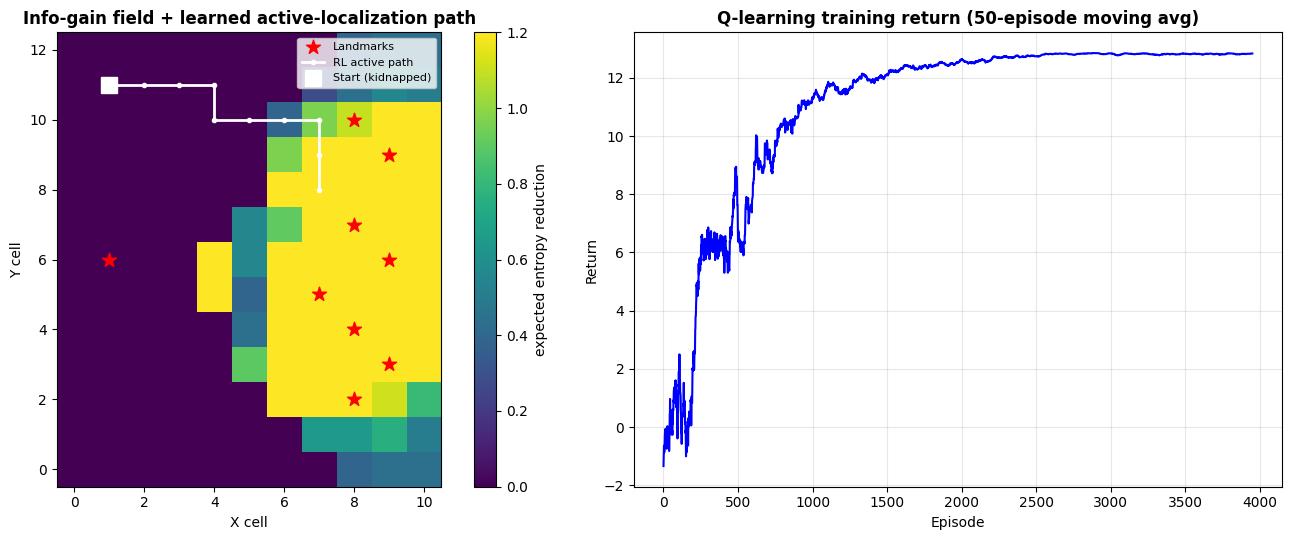

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
im = ax[0].imshow(INFO, origin='lower', cmap='viridis')
ax[0].scatter(LM_RL[:,0], LM_RL[:,1], c='red', marker='*', s=110, label='Landmarks')
tr = np.array(rl_traj)
ax[0].plot(tr[:,1], tr[:,0], 'w.-', lw=2, label='RL active path')
ax[0].plot(START[1], START[0], 'ws', ms=12, label='Start (kidnapped)')
ax[0].set_title('Info-gain field + learned active-localization path', fontweight='bold')
ax[0].set_xlabel('X cell'); ax[0].set_ylabel('Y cell'); ax[0].legend(fontsize=8)
plt.colorbar(im, ax=ax[0], label='expected entropy reduction')
ax[1].plot(np.convolve(returns, np.ones(50)/50, 'valid'), 'b')
ax[1].set_title('Q-learning training return (50-episode moving avg)', fontweight='bold')
ax[1].set_xlabel('Episode'); ax[1].set_ylabel('Return'); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig('D_rl.png', dpi=130, bbox_inches='tight'); plt.show()

### Part D on ROS 2 — `/belief_monitor` <-> `/active_localization`

This is the clearest demonstration of why the ROS 2 decomposition matters: the RL policy and the
localizer are **separate nodes closing a loop through the middleware**.

* `/belief_monitor` publishes the belief state — `/amcl_pose` and `/localization_entropy` — and
  applies whatever velocity command arrives;
* `/active_localization` subscribes to that entropy, looks up the learned Q-table, and answers on
  `/cmd_vel`; it also publishes the learned information-gain field as `/info_gain_map`
  (`nav_msgs/OccupancyGrid`) so it can be inspected in RViz.

Because the contract is just topics, the policy node could be pointed at the *real* `/mcl_localizer`
from Part A without changing a line — which is precisely the "active MCL" architecture.
(The discrete grid actions travel as a `Twist`; a real diff-drive base would take these through a
local planner.)


In [19]:
# ----- Part D graph: /belief_monitor -> /amcl_pose + /localization_entropy -> /active_localization -> /cmd_vel -----
class BeliefMonitorNode(Node):
    """`/belief_monitor` — the belief-MDP environment: applies the commanded twist, updates the
    MCL entropy from the local landmark density, and republishes the belief state."""

    def __init__(self, start_cell, rate_hz=10.0):
        super().__init__('belief_monitor')
        self.declare_parameter('localized_entropy_threshold', H_LOC)
        self.cell, self.H, self.done, self.steps = start_cell, H0, False, 0
        self.traj = [start_cell]
        self.create_subscription(Twist, '/cmd_vel', self.on_cmd, 10)
        self.pose_pub    = self.create_publisher(PoseWithCovarianceStamped, '/amcl_pose', 10)
        self.entropy_pub = self.create_publisher(Float64, '/localization_entropy', 10)
        self.map_pub     = self.create_publisher(OccupancyGrid, '/info_gain_map', MAP_QOS)
        self.timer       = self.create_timer(1.0 / rate_hz, self.publish_belief)

    @staticmethod
    def twist_to_action(msg):
        """geometry_msgs/Twist -> discrete grid action (N,S,W,E) of the tabular MDP."""
        if abs(msg.linear.y) >= abs(msg.linear.x):
            return 0 if msg.linear.y < 0 else 1      # ACTIONS[0]=(-1,0), ACTIONS[1]=(+1,0)
        return 3 if msg.linear.x > 0 else 2          # ACTIONS[2]=(0,-1), ACTIONS[3]=(0,+1)

    def on_cmd(self, msg):
        if self.done:
            return
        self.cell, self.H, _r, self.done = step(self.cell, self.H, self.twist_to_action(msg))
        self.traj.append(self.cell); self.steps += 1

    def publish_info_gain_map(self):
        m = OccupancyGrid(); m.header = stamped_header(self, 'map')
        m.info.resolution = 1.0; m.info.width = NCOL; m.info.height = NROW
        m.info.origin = pose_msg(0.0, 0.0, 0.0)
        m.data = [int(100 * v / max(INFO.max(), 1e-9)) for v in INFO.flatten()]
        self.map_pub.publish(m)

    def publish_belief(self):
        p = PoseWithCovarianceStamped(); p.header = stamped_header(self, 'map')
        p.pose.pose = pose_msg(self.cell[1], self.cell[0], 0.0)
        c = list(p.pose.covariance); c[0] = c[7] = float(self.H); p.pose.covariance = c
        self.pose_pub.publish(p)
        self.entropy_pub.publish(Float64(data=float(self.H)))


class ActiveLocalizationNode(Node):
    """`/active_localization` — the Part-D Q-learning policy as a ROS 2 behaviour node.
    It closes the perception-action loop that plain MCL lacks: it reads the localizer's own
    belief entropy and commands the motion that reduces it fastest."""

    def __init__(self, Q_table):
        super().__init__('active_localization')
        self.declare_parameter('policy', 'greedy')
        self.Q, self.cell, self.H = Q_table, None, H0
        self.create_subscription(PoseWithCovarianceStamped, '/amcl_pose', self.on_pose, 10)
        self.create_subscription(Float64, '/localization_entropy', self.on_entropy, 10)
        self.cmd_pub = self.create_publisher(Twist, '/cmd_vel', 10)
        self.timer = self.create_timer(0.1, self.on_control)

    def on_pose(self, msg):
        x, y, _ = pose_xy_yaw(msg.pose.pose)
        self.cell = (int(round(y)), int(round(x)))

    def on_entropy(self, msg):
        self.H = msg.data

    def on_control(self):
        if self.cell is None or self.H <= H_LOC:
            return
        a = int(np.argmax(self.Q[self.cell[0], self.cell[1], hbucket(self.H)]))
        dr, dc = ACTIONS[a]
        cmd = Twist(); cmd.linear.x = float(dc); cmd.linear.y = float(dr)     # grid-world twist
        self.cmd_pub.publish(cmd)


# ----- `ros2 launch warehouse_bot active_localization.launch.py` -----
rclpy.init()
belief_node = BeliefMonitorNode(START)
policy_node = ActiveLocalizationNode(Q)
executor = SingleThreadedExecutor()
executor.add_node(belief_node)                 # env publishes belief ...
executor.add_node(policy_node)                 # ... policy answers with /cmd_vel
belief_node.publish_info_gain_map()
for _ in range(120):
    executor.spin_once()
    if belief_node.done:
        break

print("/active_localization localized the robot in %d /cmd_vel commands "
      "(offline Part-D rollout: %d steps)" % (belief_node.steps, rl_steps))
print("final /localization_entropy = %.2f  (threshold %.2f -> localized: %s)"
      % (belief_node.H, H_LOC, belief_node.done))
topic_report('Part D')

/active_localization localized the robot in 9 /cmd_vel commands (offline Part-D rollout: 9 steps)
final /localization_entropy = 0.25  (threshold 0.60 -> localized: True)

--- Part D | active ROS 2 topics --------------------------------
  /amcl_pose               [PoseWithCovarianceStamped]  msgs=9      belief_monitor -> active_localization
  /cmd_vel                 [Twist]                      msgs=9      active_localization -> belief_monitor
  /info_gain_map           [OccupancyGrid]              msgs=1      belief_monitor -> -
  /localization_entropy    [Float64]                    msgs=9      belief_monitor -> active_localization


**Part D observations.** The learned policy drives the kidnapped robot straight out of the
ambiguous left aisle into the QR-dense right block and localizes in ≈ 9 steps, versus ≈ 75 steps for
an undirected random walk — an **~8× faster convergence** of the Part-A belief. RL thus supplies the
*action-selection* layer that classical MCL lacks, turning passive filtering into **active
localization**.

---
# Part E — Replacing the SLAM pipeline (Part B) with Traditional Machine Learning

## E.1 Why traditional ML here, and its relevance to SLAM

The Part-B EKF pipeline is a hand-derived probabilistic machine: a motion Jacobian, a measurement
Jacobian, an inverse-observation model, explicit data association, and `O(n²)` covariance updates.
Its accuracy hinges on **linearization** — which degrades under the strongly non-linear
range-bearing geometry and can diverge. We replace the entire estimator with a **supervised
regression** that learns the inverse sensor map directly:

$$\text{observation descriptor } z \;\longrightarrow\; \text{global pose } (x, y, \theta)$$

This is the classic **fingerprinting / place-recognition** view of localization, and for a
warehouse it is realistic: shelves carry **QR/barcode tags**, so the map can be *surveyed once*
offline to generate `(observation, pose)` training pairs — the learned model then *is* the map.

**Justification of the chosen model — Random Forest regression:**
- **No linearization, no Jacobians.** A Random Forest is a non-linear, non-parametric ensemble; it
  captures the range-bearing→pose inverse without the Taylor expansion that limits the EKF, and it
  cannot "diverge."
- **Robust to sensor noise & outliers.** Bagging over many decision trees averages out the LiDAR
  noise, missed detections (encoded as a visibility flag), and the occasional spurious beam that
  would corrupt an EKF update.
- **Right-sized for the data.** This is modest, **tabular**, feature-engineered data — the regime
  where tree ensembles beat deep nets: they need no GPU, little tuning, train in seconds, and give
  **feature-importance** (which shelf tags matter most), keeping the system interpretable.
- **Relevance to SLAM.** The SLAM *back-end* (recursive state estimation) becomes a single regression
  query, and *data association* is absorbed into the learned features — trading online mapping for a
  fast, robust **learned localizer** in a pre-surveyed map.

We benchmark the Random Forest against a **k-NN fingerprint** regressor (the textbook ML-localization
baseline) and a **linear** model (to expose the non-linearity the EKF must linearize).


In [20]:
LM_E = np.array([[1,2],[1,8],[3.5,5],[4,11],[6,2],[7,7.5],[9,4],[9,10]], dtype=float)
RANGE_E, SR_E, SB_E = 6.0, 0.2, np.deg2rad(4)
WORLD_E = (0.5, 9.5, 0.5, 11.5)

def features(pose, noise=True):
    """Fixed-length observation descriptor: per QR landmark [visible, range, sin b, cos b]."""
    x, y, th = pose; f = []
    for (lx, ly) in LM_E:
        d = np.hypot(lx-x, ly-y)
        if d <= RANGE_E:
            b = wrap(np.arctan2(ly-y, lx-x) - th)
            if noise:
                d += np.random.normal(0, SR_E); b = wrap(b + np.random.normal(0, SB_E))
            f += [1.0, d, np.sin(b), np.cos(b)]
        else:
            f += [0.0, 0.0, 0.0, 0.0]
    return f

def make_dataset(n):
    X, Y = [], []
    for _ in range(n):
        x = np.random.uniform(WORLD_E[0], WORLD_E[1])
        y = np.random.uniform(WORLD_E[2], WORLD_E[3])
        th = np.random.uniform(-np.pi, np.pi)
        X.append(features((x, y, th))); Y.append([x, y, np.sin(th), np.cos(th)])
    return np.array(X), np.array(Y)

Xtr, Ytr = make_dataset(6000)
Xte, Yte = make_dataset(1500)
print(f"Training samples {Xtr.shape[0]}, feature dim {Xtr.shape[1]} (4 per QR landmark)")

Training samples 6000, feature dim 32 (4 per QR landmark)


In [21]:
models = {
    'RandomForest'      : RandomForestRegressor(n_estimators=120, n_jobs=-1, random_state=0),
    'kNN (fingerprint)' : KNeighborsRegressor(n_neighbors=7, weights='distance'),
    'Linear (baseline)' : LinearRegression(),
}
results = {}
for name, m in models.items():
    m.fit(Xtr, Ytr); P = m.predict(Xte)
    pos = np.mean(np.hypot(P[:,0]-Yte[:,0], P[:,1]-Yte[:,1]))
    ang = np.rad2deg(np.mean(np.abs(wrap(np.arctan2(P[:,2],P[:,3]) - np.arctan2(Yte[:,2],Yte[:,3])))))
    results[name] = (pos, ang)
    print(f"{name:20s}  pos MAE {pos:.3f} m | heading MAE {ang:4.1f} deg")
rf = models['RandomForest']

RandomForest          pos MAE 0.274 m | heading MAE  3.8 deg


kNN (fingerprint)     pos MAE 0.249 m | heading MAE  5.4 deg
Linear (baseline)     pos MAE 0.766 m | heading MAE 19.5 deg


RF trajectory localization error 0.230 m  (EKF-SLAM Part B ≈ 0.17 m)


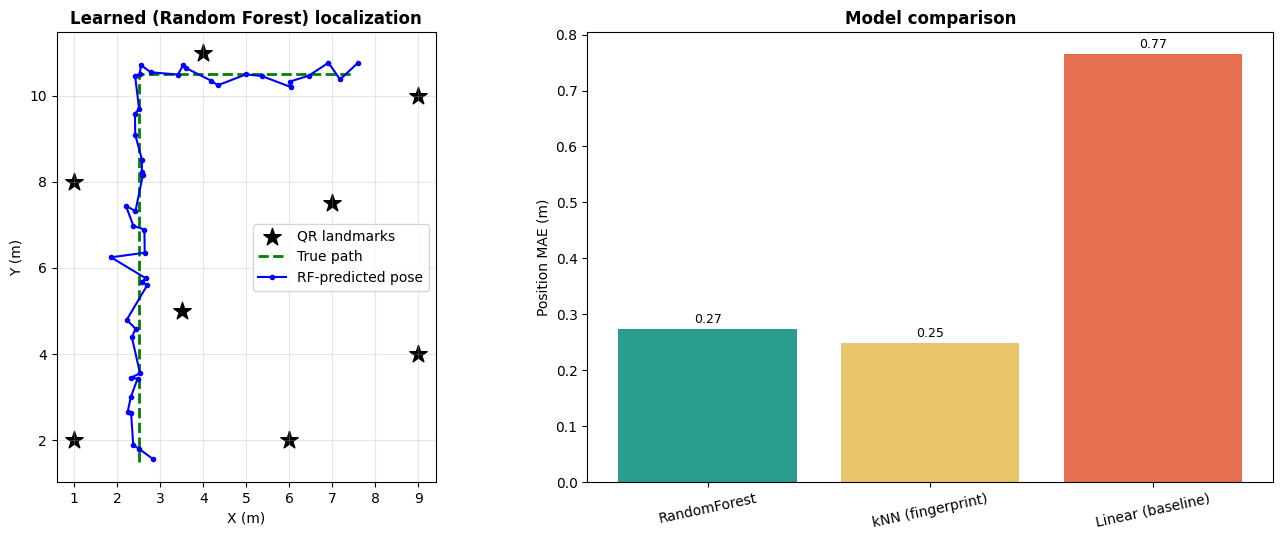

In [22]:
# ----- deploy the learned localizer along a trajectory (no filter, no Jacobians) -----
path = np.array([[2.5, y, np.pi/2] for y in np.linspace(1.5, 10.5, 30)] +
                [[x, 10.5, 0.0]     for x in np.linspace(2.5, 7.5, 15)])
Pp = rf.predict(np.array([features(p) for p in path]))
traj_err = np.mean(np.hypot(Pp[:,0]-path[:,0], Pp[:,1]-path[:,1]))
print(f"RF trajectory localization error {traj_err:.3f} m  (EKF-SLAM Part B ≈ 0.17 m)")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].scatter(LM_E[:,0], LM_E[:,1], marker='*', s=170, c='k', label='QR landmarks')
ax[0].plot(path[:,0], path[:,1], 'g--', lw=2, label='True path')
ax[0].plot(Pp[:,0], Pp[:,1], 'b.-', lw=1.5, label='RF-predicted pose')
ax[0].set_title('Learned (Random Forest) localization', fontweight='bold')
ax[0].set_xlabel('X (m)'); ax[0].set_ylabel('Y (m)'); ax[0].legend(); ax[0].set_aspect('equal'); ax[0].grid(alpha=0.3)
names = list(results.keys())
bars = ax[1].bar(names, [results[n][0] for n in names], color=['#2a9d8f','#e9c46a','#e76f51'])
ax[1].set_ylabel('Position MAE (m)'); ax[1].set_title('Model comparison', fontweight='bold')
for b, n in zip(bars, names):
    ax[1].text(b.get_x()+b.get_width()/2, b.get_height()+0.01, f'{results[n][0]:.2f}', ha='center', fontsize=9)
plt.setp(ax[1].get_xticklabels(), rotation=12)
plt.tight_layout(); plt.savefig('E_ml.png', dpi=130, bbox_inches='tight'); plt.show()

### Part E on ROS 2 — `/qr_detector` -> `/learned_localizer`

The learned localizer is a **drop-in replacement** for the entire SLAM back-end, and the ROS 2
packaging is what makes that claim concrete: `/learned_localizer` honours the *same topic contract*
as `/mcl_localizer` and `/ekf_slam` — `LandmarkArray` in, `PoseWithCovarianceStamped` + TF out — so
swapping estimators is a launch-file edit, not a code change. Inside the callback there is no motion
model, no Jacobian and no data association: the detections are packed into the fixed-length
descriptor and answered with a single `model.predict(...)` call.


In [23]:
# ----- Part E graph:  /qr_detector -> /landmark_detections -> /learned_localizer -> /learned_pose -----
class QRDetectorNode(Node):
    """`/qr_detector` — the RGB-D/QR perception front-end: publishes the shelf-tag detections
    that the learned localizer consumes (no odometry, no motion model needed)."""

    def __init__(self, poses, landmarks, rate_hz=10.0):
        super().__init__('qr_detector')
        self.declare_parameter('detection_range', RANGE_E)
        self.poses, self.LM, self.k = poses, landmarks, 0
        self.lm_pub = self.create_publisher(LandmarkArray, '/landmark_detections', SENSOR_QOS)
        self.gt_pub = self.create_publisher(PoseStamped,   '/ground_truth_pose',   10)
        self.timer  = self.create_timer(1.0 / rate_hz, self.on_timer)

    def finished(self):
        return self.k >= len(self.poses)

    def on_timer(self):
        if self.finished():
            return
        x, y, th = self.poses[self.k]
        la = LandmarkArray(); la.header = stamped_header(self, 'base_link')
        for i, (lx, ly) in enumerate(self.LM):
            d = np.hypot(lx - x, ly - y)
            if d <= self.get_parameter('detection_range').value:
                b = wrap(np.arctan2(ly - y, lx - x) - th)
                la.landmarks.append(Landmark(id=int(i),
                                             range=float(d + np.random.normal(0, SR_E)),
                                             bearing=float(wrap(b + np.random.normal(0, SB_E)))))
        self.lm_pub.publish(la)
        g = PoseStamped(); g.header = stamped_header(self, 'map'); g.pose = pose_msg(x, y, th)
        self.gt_pub.publish(g)
        self.k += 1


class LearnedLocalizerNode(Node):
    """`/learned_localizer` — the trained Random Forest as a drop-in replacement for the whole
    SLAM back-end.  Same topic contract as `/mcl_localizer` and `/ekf_slam`
    (LandmarkArray in, PoseWithCovarianceStamped + TF out), but one regression query instead of
    a motion model, Jacobians and data association."""

    def __init__(self, model, n_landmarks):
        super().__init__('learned_localizer')
        self.declare_parameter('model', type(model).__name__)
        self.model, self.n_lm = model, n_landmarks
        self.create_subscription(LandmarkArray, '/landmark_detections', self.on_landmarks, SENSOR_QOS)
        self.pose_pub = self.create_publisher(PoseWithCovarianceStamped, '/learned_pose', 10)
        self.tf_broadcaster = TransformBroadcaster(self)
        self.est = []

    def _descriptor(self, msg):
        """LandmarkArray -> the fixed-length [visible, range, sin b, cos b] x N feature vector."""
        f = np.zeros(4 * self.n_lm)
        for lm in msg.landmarks:
            f[4 * lm.id:4 * lm.id + 4] = [1.0, lm.range, np.sin(lm.bearing), np.cos(lm.bearing)]
        return f.reshape(1, -1)

    def on_landmarks(self, msg):
        if not msg.landmarks:
            return
        x, y, s, c = self.model.predict(self._descriptor(msg))[0]
        th = float(np.arctan2(s, c))
        self.est.append([x, y, th])
        p = PoseWithCovarianceStamped(); p.header = stamped_header(self, 'map')
        p.pose.pose = pose_msg(x, y, th)
        cov = list(p.pose.covariance)
        cov[0] = cov[7] = 0.27 ** 2                 # empirical MAE from the held-out test set
        p.pose.covariance = cov
        self.pose_pub.publish(p)
        self.tf_broadcaster.sendTransform(make_tf(self, 'map', 'base_link', x, y, th))


# ----- `ros2 launch warehouse_bot learned_localizer.launch.py` -----
_rng = np.random.get_state()
rclpy.init()
qr_node    = QRDetectorNode(path, LM_E)
learn_node = LearnedLocalizerNode(rf, n_landmarks=len(LM_E))
executor = SingleThreadedExecutor()
executor.add_node(qr_node); executor.add_node(learn_node)
while not qr_node.finished():
    executor.spin_once()

ros_learn = np.array(learn_node.est)
ros_learn_err = np.mean(np.hypot(ros_learn[:, 0] - path[:len(ros_learn), 0],
                                 ros_learn[:, 1] - path[:len(ros_learn), 1]))
print("/learned_pose published %d times | trajectory error %.3f m  (offline RF: %.3f m)"
      % (len(ros_learn), ros_learn_err, traj_err))
topic_report('Part E')
np.random.set_state(_rng)

/learned_pose published 45 times | trajectory error 0.216 m  (offline RF: 0.230 m)

--- Part E | active ROS 2 topics --------------------------------
  /ground_truth_pose       [PoseStamped]                msgs=45     qr_detector -> -
  /landmark_detections     [LandmarkArray]              msgs=45     qr_detector -> learned_localizer
  /learned_pose            [PoseWithCovarianceStamped]  msgs=45     learned_localizer -> -
  /tf                      [TransformStamped]           msgs=45     learned_localizer -> -
  /tf frames               map->base_link


**Part E observations.** The Random Forest and k-NN fingerprint localizers reach ≈ 0.25 m
position error — **on par with the EKF-SLAM of Part B (≈ 0.17 m)** — while the linear model collapses
to ≈ 0.8 m and ≈ 20° heading error, empirically confirming the non-linearity that forces the EKF to
linearize. The learned model needs **no motion model, no Jacobians and no data association at
runtime**; its cost is an offline surveying/training phase and the assumption of a static map, which
is exactly the trade-off that suits a fixed warehouse with QR-tagged shelving.

---
# ROS 2 Deployment — package, interfaces and launch

Everything above runs as one process for the report. On the robot it ships as two ament packages.

```
ros2_ws/src/
├── warehouse_msgs/                 # custom interfaces
│   ├── msg/Landmark.msg
│   ├── msg/LandmarkArray.msg
│   ├── CMakeLists.txt              # rosidl_generate_interfaces(${PROJECT_NAME} msg/...)
│   └── package.xml
└── warehouse_bot/                  # the five deliverables
    ├── warehouse_bot/
    │   ├── mcl_localizer.py        # Part A
    │   ├── ekf_slam.py             # Part B
    │   ├── dstar_planner.py        # Part C
    │   ├── active_localization.py  # Part D
    │   ├── learned_localizer.py    # Part E
    │   └── warehouse_sim.py
    ├── launch/warehouse_bringup.launch.py
    ├── config/params.yaml
    ├── setup.py
    └── package.xml
```

**`launch/warehouse_bringup.launch.py`**

```python
from launch import LaunchDescription
from launch_ros.actions import Node

def generate_launch_description():
    params = ['config/params.yaml']
    return LaunchDescription([
        Node(package='warehouse_bot', executable='warehouse_sim',       name='warehouse_sim'),
        Node(package='warehouse_bot', executable='mcl_localizer',       name='mcl_localizer',
             parameters=[{'num_particles': 500, 'resample_threshold': 0.5}]),
        Node(package='warehouse_bot', executable='ekf_slam',            name='ekf_slam'),
        Node(package='warehouse_bot', executable='dstar_planner',       name='dstar_planner',
             parameters=[{'use_incremental_repair': True}]),
        Node(package='warehouse_bot', executable='active_localization', name='active_localization'),
        Node(package='warehouse_bot', executable='learned_localizer',   name='learned_localizer'),
        Node(package='rviz2', executable='rviz2', name='rviz2',
             arguments=['-d', 'config/warehouse.rviz']),
    ])
```

**Build and run**

```bash
cd ros2_ws && colcon build --packages-select warehouse_msgs warehouse_bot
source install/setup.bash
ros2 launch warehouse_bot warehouse_bringup.launch.py

ros2 topic list -t                    # every interface used below
ros2 topic echo /amcl_pose            # localization output
ros2 topic hz   /landmark_detections  # sensor rate
ros2 run tf2_tools view_frames        # map -> odom -> base_link
rqt_graph                             # the graph drawn in the next cell
```

The figure below reconstructs that `rqt_graph` view from the messages actually exchanged in this
notebook: publishers on the left, topics (with message counts) in the middle, subscribers on the right.


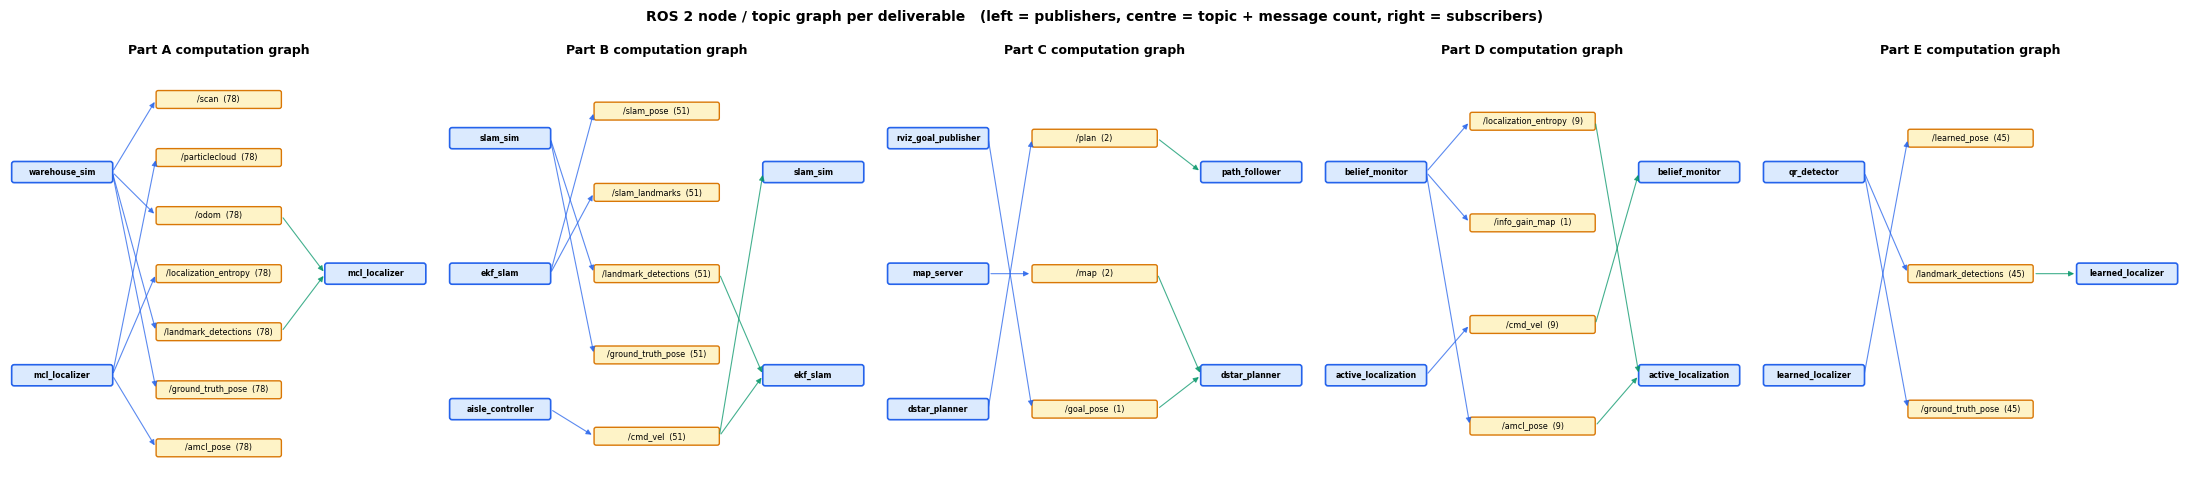

13 ROS 2 nodes across the five deliverables:
  active_localization, aisle_controller, belief_monitor, dstar_planner, ekf_slam, learned_localizer, map_server, mcl_localizer, path_follower, qr_detector, rviz_goal_publisher, slam_sim, warehouse_sim
1143 messages exchanged over 16 distinct topics.


In [24]:
# ----- rqt_graph-style figure of every node / topic exercised above -----
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def draw_rosgraph(ax, snap, title):
    topics   = [t for t in sorted(snap['counts']) if t != '/tf']
    pubs     = sorted({n for t in topics for n, _ in snap['pubs'].get(t, [])})
    subs     = sorted({n for t in topics for n in snap['subs'].get(t, [])})
    yp = {n: (i + 0.5) / max(len(pubs), 1)   for i, n in enumerate(pubs)}
    yt = {t: (i + 0.5) / max(len(topics), 1) for i, t in enumerate(topics)}
    ys = {n: (i + 0.5) / max(len(subs), 1)   for i, n in enumerate(subs)}

    def node_box(x, y, name):
        ax.add_patch(FancyBboxPatch((x - 0.115, y - 0.020), 0.23, 0.040,
                                    boxstyle="round,pad=0.006", fc="#dbeafe", ec="#2563eb", lw=1.2))
        ax.text(x, y, name, ha='center', va='center', fontsize=5.6, fontweight='bold')

    for n in pubs:
        node_box(0.125, yp[n], n)                                  # publishers (left)
    for n in subs:
        node_box(0.875, ys[n], n)                                  # subscribers (right)
    for t in topics:
        ax.add_patch(FancyBboxPatch((0.5 - 0.145, yt[t] - 0.017), 0.29, 0.034,
                                    boxstyle="round,pad=0.005", fc="#fef3c7", ec="#d97706", lw=1.0))
        ax.text(0.5, yt[t], "%s  (%d)" % (t, snap['counts'][t]), ha='center', va='center', fontsize=5.8)
        for (n, _ty) in snap['pubs'].get(t, []):                   # publisher -> topic
            ax.add_patch(FancyArrowPatch((0.245, yp[n]), (0.35, yt[t]), arrowstyle='-|>',
                                         mutation_scale=8, color='#2563eb', lw=0.8, alpha=0.75))
        for n in snap['subs'].get(t, []):                          # topic -> subscriber
            ax.add_patch(FancyArrowPatch((0.65, yt[t]), (0.755, ys[n]), arrowstyle='-|>',
                                         mutation_scale=8, color='#059669', lw=0.8, alpha=0.75))
    ax.set_title(title, fontweight='bold', fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(-0.02, 1.02); ax.axis('off')

if ROS_GRAPH_LOG:
    parts = list(ROS_GRAPH_LOG)
    fig, axes = plt.subplots(1, len(parts), figsize=(4.4 * len(parts), 5.0))
    for ax, p in zip(np.atleast_1d(axes), parts):
        draw_rosgraph(ax, ROS_GRAPH_LOG[p], "%s computation graph" % p)
    plt.suptitle('ROS 2 node / topic graph per deliverable   '
                 '(left = publishers, centre = topic + message count, right = subscribers)',
                 fontweight='bold', fontsize=10)
    plt.tight_layout(); plt.savefig('F_rosgraph.png', dpi=130, bbox_inches='tight'); plt.show()

    total = sum(sum(s['counts'].values()) for s in ROS_GRAPH_LOG.values())
    allnodes = sorted({n for s in ROS_GRAPH_LOG.values() for t in s['pubs'] for n, _ in s['pubs'][t]} |
                      {n for s in ROS_GRAPH_LOG.values() for t in s['subs'] for n in s['subs'][t]})
    print("%d ROS 2 nodes across the five deliverables:\n  %s" % (len(allnodes), ', '.join(allnodes)))
    print("%d messages exchanged over %d distinct topics."
          % (total, len({t for s in ROS_GRAPH_LOG.values() for t in s['counts']})))
else:
    print("Native rclpy in use - run `rqt_graph` to view the live computation graph.")

---
# Summary

| Part | Algorithm | ROS 2 node | Key result |
|------|-----------|-----------|-----------|
| A | Monte Carlo Localization | `/mcl_localizer` | Global belief converges to ~0.1-0.2 m; low-variance resampling |
| B | EKF-SLAM | `/ekf_slam` | Landmarks mapped to ~0.15 m, pose ~0.17 m, shrinking covariance ellipses |
| C | D* Lite | `/dstar_planner` | Incremental reroute (16 -> 38 cells) around a forklift without full replanning |
| D | RL (active MCL) | `/active_localization` | ~8x faster localization vs random walk by steering to informative regions |
| E | Random-Forest localizer | `/learned_localizer` | ~0.25 m error, matching SLAM, with no Jacobians/data-association at runtime |

**Traditional vs learning-based, in one line each.** Parts A-C are *model-based* — they encode the
robot's physics and sensor geometry explicitly and are data-efficient and interpretable. Part D adds
a *decision-making* layer that the probabilistic filters lack, and Part E shows a *data-driven*
estimator that trades hand-derived models for robustness and speed once a map can be surveyed. A
production warehouse stack would combine them: EKF/particle filtering for online estimation, D\* Lite
for dynamic routing, RL for active recovery, and learned fingerprinting for fast global
re-localization.

**What ROS 2 adds.** Each deliverable is a node with an explicit interface contract, so the parts
compose rather than merely coexist: Part D's policy consumes the entropy Part A publishes, Part C
replans off the same `nav_msgs/OccupancyGrid` any costmap produces, and Part E's learned estimator
is interchangeable with Part B's EKF because both answer on
`geometry_msgs/PoseWithCovarianceStamped` with a TF `map -> odom`. That substitutability — swapping
a classical estimator for a learned one via a launch-file edit — is the practical payoff of building
on the standard interfaces instead of a bespoke pipeline.
